# Modeling & Evaluation: Clustering Profil Pertanahan Desa Indonesia

Notebook ini menjalankan tahap **Phase 4 (Modeling)** dan **Phase 5 (Evaluation)** di atas data siap-pakai dari `data/clustering_ready/`.

**Aturan Main dari `data/clustering_ready/README.md`:**
1. Selalu baca `kode8` sebagai teks (`str`) agar *leading zero* tetap terjaga.
2. Gunakan `X_A_scaled.csv` / `X_B_scaled.csv` apa adanya — **jangan rescale ulang**.
3. Kolom di `interpretation_columns.csv` (termasuk banjir, RDTR, tahun) **hanya untuk profiling/evaluasi**, bukan input clustering.
4. Desa di `place_later.csv` tidak dibuang diam-diam: 1.950 desa tanpa persil dilaporkan sebagai kelompok sendiri, dan 122 baris tereksklusi tidak di-*assign*.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#444444"})

ROOT = Path.cwd().parent if (Path.cwd().parent / "data" / "clustering_ready").exists() else Path.cwd()
DATA_DIR = ROOT / "data" / "clustering_ready"
OUT_DIR = ROOT / "modeling" / "outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

COMP_COLS = ["s_hak_milik", "s_hgb", "s_hgu", "s_hak_pakai", "s_kosong", "s_other"]
OTHER_COLS = ["log_parcel_density", "log_mean_parcel"]
RAW_SHARE_COLS = [
    "hak_milik_share_luas",
    "hgb_share_luas",
    "hgu_share_luas",
    "hak_pakai_share_luas",
    "kosong_share_luas",
    "other_share_luas",
]
SHARE_LABELS = {
    "hak_milik_share_luas": "Hak Milik (SHM)",
    "hgb_share_luas": "HGB",
    "hgu_share_luas": "HGU",
    "hak_pakai_share_luas": "Hak Pakai",
    "kosong_share_luas": "Kosong (Belum Hak)",
    "other_share_luas": "Lainnya (<1%)",
}

read_opts = dict(index_col="kode8", dtype={"kode8": str})
x_a_scaled = pd.read_csv(DATA_DIR / "X_A_scaled.csv", **read_opts)
x_a = pd.read_csv(DATA_DIR / "X_A.csv", **read_opts)
village_ids = pd.read_csv(DATA_DIR / "village_ids.csv", **read_opts)
interp = pd.read_csv(DATA_DIR / "interpretation_columns.csv", **read_opts)
place_later = pd.read_csv(DATA_DIR / "place_later.csv", **read_opts)
with open(DATA_DIR / "transform_recipe.json", encoding="utf-8") as f:
    recipe = json.load(f)

print(f"X_A_scaled : {x_a_scaled.shape}")
print(f"village_ids: {village_ids.shape}")
print(f"interp     : {interp.shape}")
print(f"place_later: {place_later.shape}")
x_a_scaled.head()

X_A_scaled : (77770, 8)
village_ids: (79842, 7)
interp     : (79842, 33)
place_later: (2744, 20)


,s_hak_milik,s_hgb,s_hgu,s_hak_pakai,s_kosong,s_other,log_parcel_density,log_mean_parcel
kode8,,,,,,,,
01010101,-1.415300,0.137282,-0.165198,2.642250,0.166919,-0.126676,0.533604,0.048824
01010102,-0.691650,0.116154,-0.165198,2.740160,-0.845902,0.032075,0.656693,-0.348591
01010103,0.405771,0.574030,-0.165198,0.551607,0.131875,-0.014368,1.115330,-1.109440
01010104,-1.324440,0.674642,-0.165198,2.548420,0.049517,0.187414,0.864807,-0.559651
01010105,0.111128,0.567090,-0.165198,1.620670,-0.367027,0.150282,1.270550,-1.291960


## Step 1: Cek Ombak — Kenalan sama `X_A_scaled.csv` & Uji *Cluster Tendency*

Sebelum memanggil algoritma clustering, kita cek dulu integritas matriks, sebaran varians fitur, contoh desa nyata, struktur ruang PCA, serta kecenderungan berkelompok (*cluster tendency*).

In [2]:
# 1.1 Sanity checks & verifikasi transform_recipe.json
assert x_a_scaled.shape == (77770, 8), f"Unexpected shape: {x_a_scaled.shape}"
assert x_a.shape == (77770, 8), f"Unexpected X_A shape: {x_a.shape}"
assert list(x_a_scaled.columns) == COMP_COLS + OTHER_COLS
assert x_a_scaled.index.equals(x_a.index), "Index mismatch X_A_scaled vs X_A"
assert not x_a_scaled.isna().any().any(), "NaN found in X_A_scaled"
assert np.isfinite(x_a_scaled.to_numpy()).all(), "Inf found in X_A_scaled"
assert (x_a_scaled.index.str.len() == 8).all(), "kode8 length is not 8"
assert x_a_scaled.index.is_unique, "Duplicate kode8 in X_A_scaled"
assert x_a_scaled.index.isin(village_ids.index).all()
assert x_a_scaled.index.isin(interp.index).all()

sc_a = recipe["scaling"]["A"]
rebuilt = pd.DataFrame(index=x_a.index)
for col in sc_a["comp_cols"]:
    rebuilt[col] = (x_a[col] - sc_a["comp_center"][col]) * sc_a["comp_factor"]
for col in sc_a["other_cols"]:
    rebuilt[col] = (x_a[col] - sc_a["center"][col]) / sc_a["scale"][col]
max_rebuild_diff = float(np.max(np.abs(rebuilt[x_a_scaled.columns] - x_a_scaled).to_numpy()))

vars_series = x_a_scaled.var(ddof=1)
comp_var = float(vars_series[COMP_COLS].sum())
other_var = float(vars_series[OTHER_COLS].sum())
total_var = comp_var + other_var

print(f"Leading-zero kode8 preserved : {int(x_a_scaled.index.str.startswith('0').sum()):,} baris")
print(f"Max diff rebuild vs recipe   : {max_rebuild_diff:.2e}")
print(
    f"Varians Komposisi (6 kolom)  : {comp_var:.3f} ({100*comp_var/total_var:.1f}%) | "
    f"Density+Size (2 kolom): {other_var:.3f} ({100*other_var/total_var:.1f}%)"
)

col_stats = pd.DataFrame({
    "median": x_a_scaled.median(),
    "mean": x_a_scaled.mean(),
    "std": x_a_scaled.std(ddof=1),
    "var": vars_series,
    "p05": x_a_scaled.quantile(0.05),
    "p95": x_a_scaled.quantile(0.95),
}).round(4)
display(col_stats)

meta_fit = village_ids.join(interp, how="inner").loc[x_a_scaled.index]
dom_counts = meta_fit[RAW_SHARE_COLS].idxmax(axis=1).map(SHARE_LABELS).value_counts()
dom_df = pd.DataFrame({
    "jumlah_desa": dom_counts,
    "persen": (dom_counts / len(meta_fit) * 100).round(2),
})
print("\nTipe wilayah di fit set A:", meta_fit["tipe"].value_counts().to_dict())
display(dom_df)

Leading-zero kode8 preserved : 24,852 baris
Max diff rebuild vs recipe   : 1.35e-05
Varians Komposisi (6 kolom)  : 5.000 (70.1%) | Density+Size (2 kolom): 2.134 (29.9%)


,median,mean,std,var,p05,p95
s_hak_milik,0.2974,-0.0000,1.1851,1.4045,-2.5241,1.3382
s_hgb,-0.2844,0.0000,0.6070,0.3684,-0.2844,1.3007
s_hgu,-0.1652,-0.0000,0.7183,0.5159,-0.1652,1.1360
s_hak_pakai,-0.2655,0.0000,0.8430,0.7107,-0.7479,1.6077
s_kosong,0.0584,-0.0000,1.3811,1.9074,-2.1263,2.1487
s_other,-0.1267,0.0000,0.3050,0.0930,-0.1267,0.3554
log_parcel_density,0.0000,-0.1532,0.9916,0.9832,-2.0228,1.0861
log_mean_parcel,0.0000,0.1602,1.0726,1.1504,-1.2704,1.9054



Tipe wilayah di fit set A: {'Desa': 62361, 'Kelurahan': 15409}


,jumlah_desa,persen
Hak Milik (SHM),47458,61.02
Kosong (Belum Hak),24405,31.38
Hak Pakai,2417,3.11
HGU,2281,2.93
HGB,969,1.25
Lainnya (<1%),240,0.31


In [3]:
# 1.2 Contoh 5 desa nyata yang mewakili karakter ekstrem & transisi
queries = [
    (
        "Kelurahan Urban (SHM + HGB tinggi)",
        (meta_fit["tipe"] == "Kelurahan")
        & (meta_fit["hak_milik_share_luas"] > 0.70)
        & (meta_fit["hgb_share_luas"] > 0.12)
        & (meta_fit["jumlah_persil"] >= 1000),
        "jumlah_persil",
    ),
    (
        "Desa Dominan Kosong (Belum Bersertifikat)",
        (meta_fit["tipe"] == "Desa")
        & (meta_fit["kosong_share_luas"] > 0.92)
        & (meta_fit["jumlah_persil"] >= 200),
        "jumlah_persil",
    ),
    (
        "Desa Perkebunan (Dominan HGU)",
        (meta_fit["hgu_share_luas"] > 0.85) & (meta_fit["jumlah_persil"] >= 20),
        "hgu_share_luas",
    ),
    (
        "Wilayah Dominan Hak Pakai (Pemerintah/Fasum)",
        (meta_fit["hak_pakai_share_luas"] > 0.75) & (meta_fit["jumlah_persil"] >= 30),
        "jumlah_persil",
    ),
    (
        "Desa Campuran / Transisi (SHM ~50% + Kosong ~45%)",
        (meta_fit["tipe"] == "Desa")
        & (meta_fit["hak_milik_share_luas"].between(0.45, 0.55))
        & (meta_fit["kosong_share_luas"].between(0.40, 0.50))
        & (meta_fit["jumlah_persil"] >= 500),
        "jumlah_persil",
    ),
]

example_rows = []
examples_json = []
for label, mask, sort_col in queries:
    sub = meta_fit.loc[mask].sort_values(sort_col, ascending=False)
    pick_idx = len(sub) // 2 if "Campuran" in label else 0
    kode8 = str(sub.index[pick_idx])
    r = sub.iloc[pick_idx]
    example_rows.append({
        "profil": label,
        "kode8": kode8,
        "nama": r["nama"],
        "tipe": r["tipe"],
        "kabupaten": r["kabupaten"],
        "provinsi": r["provinsi"],
        "persil": int(r["jumlah_persil"]),
        "SHM%": round(r["hak_milik_share_luas"] * 100, 1),
        "Kosong%": round(r["kosong_share_luas"] * 100, 1),
        "HGB%": round(r["hgb_share_luas"] * 100, 1),
        "HGU%": round(r["hgu_share_luas"] * 100, 1),
        "Pakai%": round(r["hak_pakai_share_luas"] * 100, 1),
    })
    examples_json.append({
        "profile": label,
        "kode8": kode8,
        "nama": str(r["nama"]),
        "kecamatan": str(r["kecamatan"]),
        "kabupaten": str(r["kabupaten"]),
        "provinsi": str(r["provinsi"]),
        "tipe": str(r["tipe"]),
        "jumlah_persil": int(r["jumlah_persil"]),
        "luas_desa_ha": float(r["luas_desa"] / 10000.0),
        "raw_shares": {
            "hak_milik": float(r["hak_milik_share_luas"]),
            "hgb": float(r["hgb_share_luas"]),
            "hgu": float(r["hgu_share_luas"]),
            "hak_pakai": float(r["hak_pakai_share_luas"]),
            "kosong": float(r["kosong_share_luas"]),
            "other": float(r["other_share_luas"]),
        },
        "scaled_values": {k: float(v) for k, v in x_a_scaled.loc[kode8].items()},
    })

display(pd.DataFrame(example_rows))

,profil,kode8,nama,tipe,kabupaten,provinsi,persil,SHM%,Kosong%,HGB%,HGU%,Pakai%
0,Kelurahan Urban (SHM + HGB tinggi),06010903,Mayang Mangurai,Kelurahan,Kota Jambi,Jambi,13927,77.8,3.2,15.2,0.0,3.6
1,Desa Dominan Kosong (Belum Bersertifikat),12301108,Arjowilangun,Desa,Malang,Jawa Timur,11812,1.2,98.4,0.3,0.0,0.1
2,Desa Perkebunan (Dominan HGU),16090306,Mulupan,Desa,Kutai Timur,Kalimantan Timur,32,0.0,0.0,0.0,100.0,0.0
3,Wilayah Dominan Hak Pakai (Pemerintah/Fasum),05050101,Bangkinang,Kelurahan,KAMPAR,Riau,5172,4.9,11.1,0.3,0.0,83.8
4,Desa Campuran / Transisi (SHM ~50% + Kosong ~45%),11260808,Tanjungrejo,Desa,Purworejo,Jawa Tengah,2051,46.5,40.4,0.0,0.0,12.4


,Varians (%),Kumulatif (%)
PC1,39.66,39.66
PC2,27.98,67.64
PC3,13.51,81.16
PC4,7.48,88.64
PC5,4.91,93.55
PC6,3.58,97.12
PC7,1.75,98.88
PC8,1.12,100.00


,PC1,PC2,PC3,PC4
s_hak_milik,-0.608,-0.120,-0.528,-0.168
s_hgb,-0.025,-0.096,0.202,0.293
s_hgu,0.060,0.259,0.040,0.739
s_hak_pakai,-0.117,-0.052,0.749,-0.251
s_kosong,0.744,-0.341,-0.236,-0.232
s_other,-0.013,-0.031,0.046,0.041
log_parcel_density,-0.004,-0.619,-0.085,0.470
log_mean_parcel,0.241,0.637,-0.230,0.027


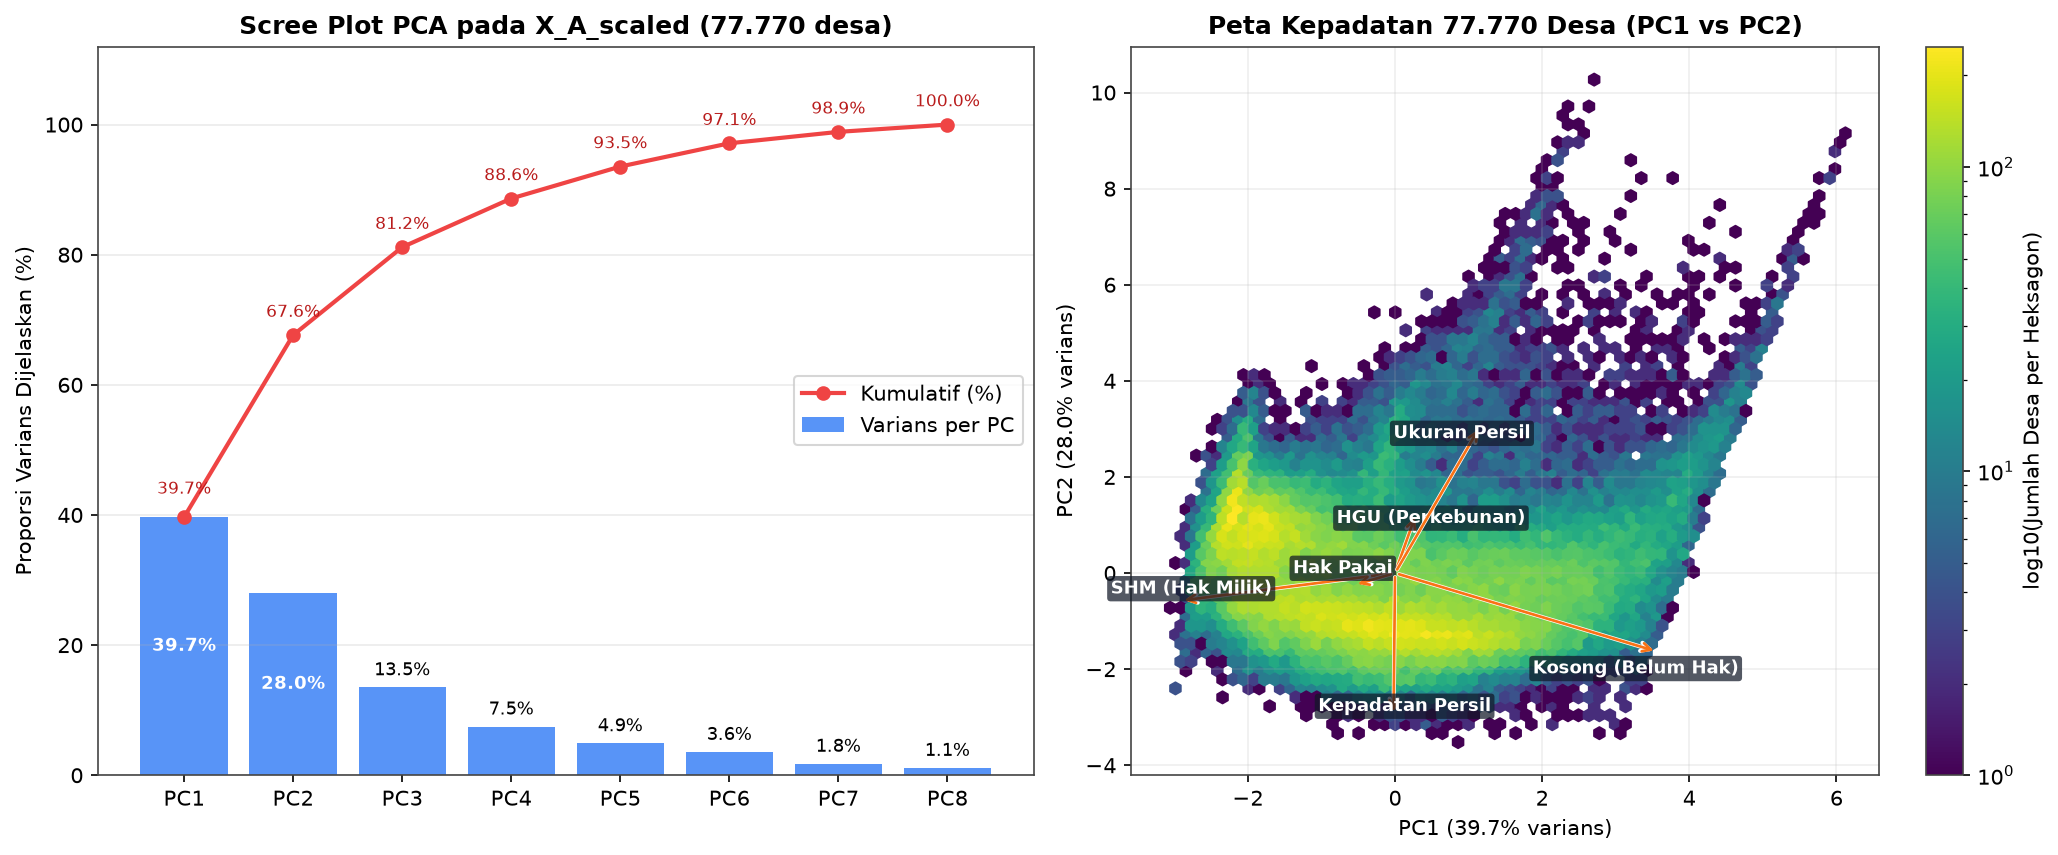

In [4]:
# 1.3 PCA pada seluruh 77.770 desa + Peta Kepadatan 2D
pca = PCA(n_components=x_a_scaled.shape[1], random_state=42)
pca_scores = pca.fit_transform(x_a_scaled.to_numpy())

ev_pct = pca.explained_variance_ratio_ * 100.0
cum_pct = np.cumsum(ev_pct)
pca_var_df = pd.DataFrame(
    {"Varians (%)": ev_pct.round(2), "Kumulatif (%)": cum_pct.round(2)},
    index=[f"PC{i}" for i in range(1, 9)],
)
loadings_df = pd.DataFrame(
    pca.components_[:4].T,
    index=x_a_scaled.columns,
    columns=["PC1", "PC2", "PC3", "PC4"],
).round(3)

display(pca_var_df)
display(loadings_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8), dpi=150)
pcs = np.arange(1, len(ev_pct) + 1)
ax0 = axes[0]
bars = ax0.bar(pcs, ev_pct, color="#3b82f6", alpha=0.85, label="Varians per PC")
ax0.plot(pcs, cum_pct, color="#ef4444", marker="o", linewidth=2, label="Kumulatif (%)")
for bar, val in zip(bars, ev_pct):
    if val >= 20.0:
        ax0.text(bar.get_x() + bar.get_width() / 2, val / 2, f"{val:.1f}%",
                 ha="center", va="center", fontsize=8.5, fontweight="bold", color="white")
    else:
        ax0.text(bar.get_x() + bar.get_width() / 2, val + 1.2, f"{val:.1f}%",
                 ha="center", va="bottom", fontsize=8.5)
for idx_pc, (x_i, y_i) in enumerate(zip(pcs, cum_pct)):
    y_off = 3.0 if idx_pc == 0 else 2.2
    ax0.text(x_i, y_i + y_off, f"{y_i:.1f}%", ha="center", va="bottom", fontsize=8, color="#b91c1c")
ax0.set_xticks(pcs)
ax0.set_xticklabels([f"PC{i}" for i in pcs])
ax0.set_ylim(0, 112)
ax0.set_ylabel("Proporsi Varians Dijelaskan (%)")
ax0.set_title("Scree Plot PCA pada X_A_scaled (77.770 desa)", fontweight="bold")
ax0.legend(loc="center right", frameon=True)
ax0.grid(axis="y", alpha=0.25)

ax1 = axes[1]
hb = ax1.hexbin(pca_scores[:, 0], pca_scores[:, 1], gridsize=65, bins="log", cmap="viridis", mincnt=1)
cb = fig.colorbar(hb, ax=ax1)
cb.set_label("log10(Jumlah Desa per Heksagon)")

arrow_cols = [
    ("s_hak_milik", "SHM (Hak Milik)", (0.15, 0.25)),
    ("s_kosong", "Kosong (Belum Hak)", (-0.30, -0.35)),
    ("s_hgu", "HGU (Perkebunan)", (0.20, -0.10)),
    ("s_hak_pakai", "Hak Pakai", (-0.15, 0.35)),
    ("log_parcel_density", "Kepadatan Persil", (0.15, 0.20)),
    ("log_mean_parcel", "Ukuran Persil", (-0.25, -0.15)),
]
scale_arrow = 4.8
for col_name, label, offset in arrow_cols:
    j = list(x_a_scaled.columns).index(col_name)
    dx = pca.components_[0, j] * scale_arrow
    dy = pca.components_[1, j] * scale_arrow
    ax1.annotate("", xy=(dx, dy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#ffffff", lw=2.0))
    ax1.annotate("", xy=(dx, dy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#f97316", lw=1.3))
    ax1.text(
        dx + offset[0], dy + offset[1], label, color="white", fontsize=8.5, fontweight="bold",
        ha="center", va="center", bbox=dict(boxstyle="round,pad=0.2", fc="#111827", alpha=0.72, ec="none"),
    )
ax1.set_xlabel(f"PC1 ({ev_pct[0]:.1f}% varians)")
ax1.set_ylabel(f"PC2 ({ev_pct[1]:.1f}% varians)")
ax1.set_title("Peta Kepadatan 77.770 Desa (PC1 vs PC2)", fontweight="bold")
ax1.grid(alpha=0.2)

fig.tight_layout()
plt.show()

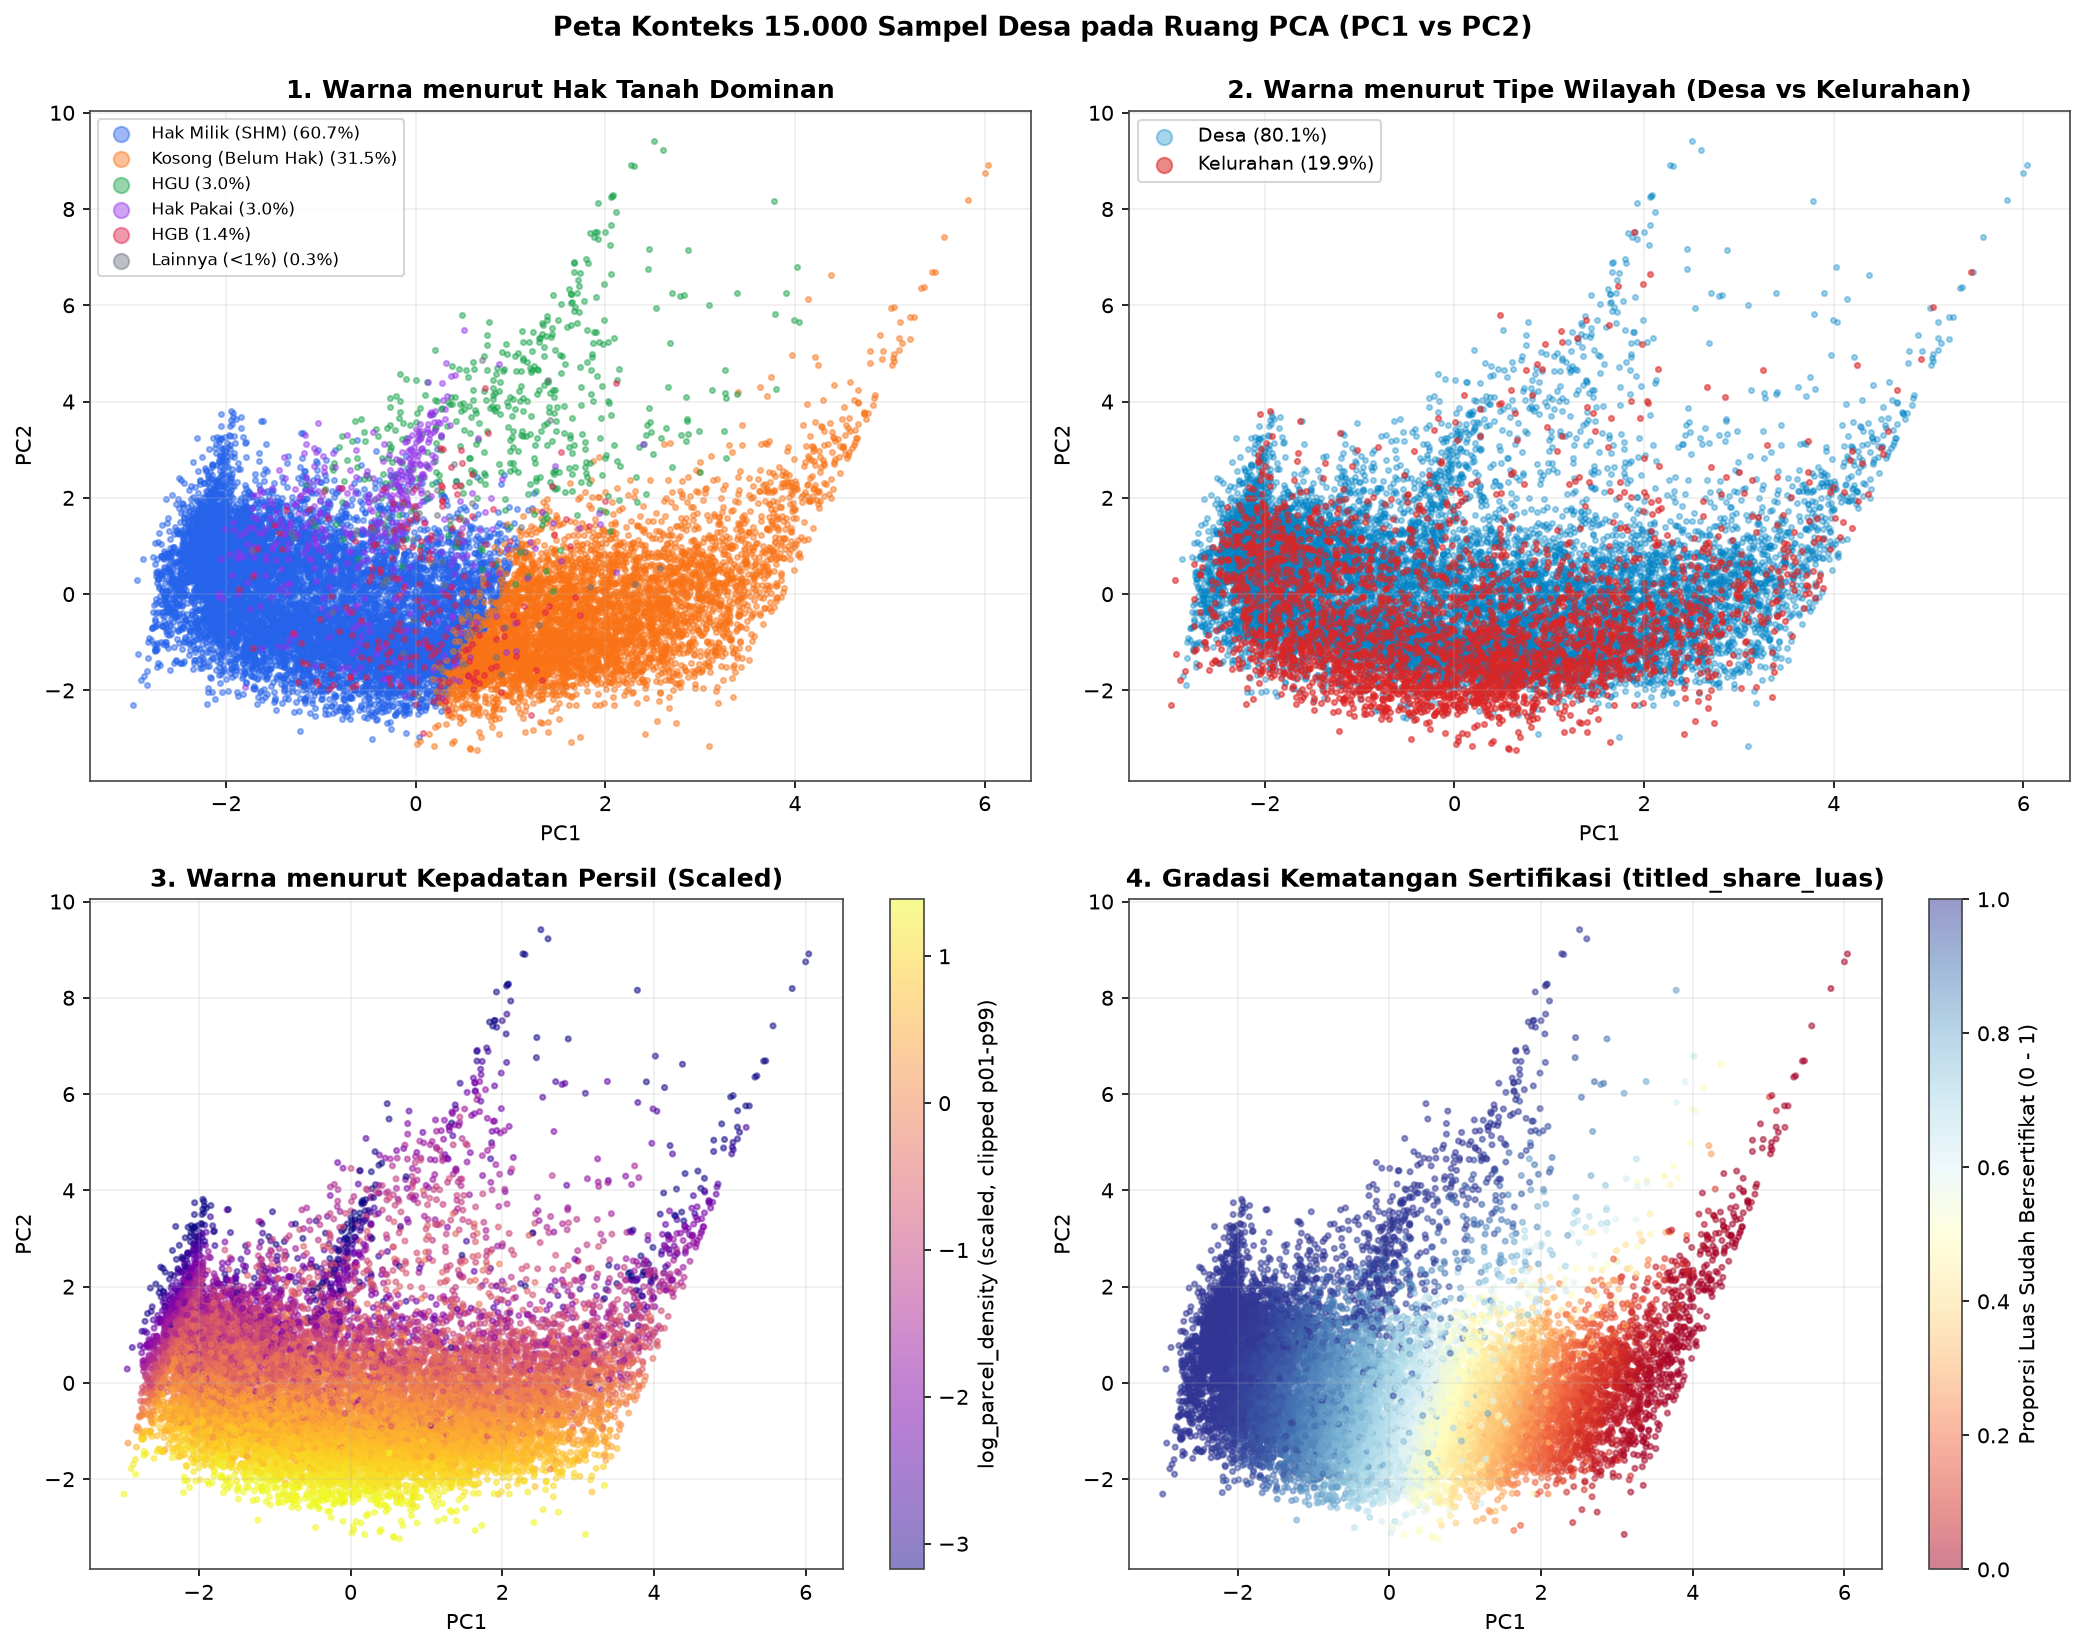

In [5]:
# 1.4 Peta Konteks pada 15.000 sampel desa (seed=42)
rng = np.random.default_rng(42)
sample_pos = rng.choice(len(x_a_scaled), size=15000, replace=False)
sample_ids = x_a_scaled.index[sample_pos]
meta_s = meta_fit.loc[sample_ids]
x_s = x_a_scaled.loc[sample_ids]
pc1_s = pca_scores[sample_pos, 0]
pc2_s = pca_scores[sample_pos, 1]

fig, axes = plt.subplots(2, 2, figsize=(14, 11), dpi=150)

ax = axes[0, 0]
dom = meta_s[RAW_SHARE_COLS].idxmax(axis=1).map(SHARE_LABELS)
palette = {
    "Hak Milik (SHM)": "#2563eb",
    "Kosong (Belum Hak)": "#f97316",
    "HGU": "#16a34a",
    "Hak Pakai": "#9333ea",
    "HGB": "#e11d48",
    "Lainnya (<1%)": "#6b7280",
}
for label_name, color in palette.items():
    mask = dom == label_name
    if mask.any():
        ax.scatter(pc1_s[mask], pc2_s[mask], s=6, alpha=0.45, color=color,
                   label=f"{label_name} ({mask.mean()*100:.1f}%)", rasterized=True)
ax.set_title("1. Warna menurut Hak Tanah Dominan", fontweight="bold")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.legend(markerscale=3, fontsize=8, loc="upper left", frameon=True)
ax.grid(alpha=0.2)

ax = axes[0, 1]
for tipe_val, color, alpha in [("Desa", "#0284c7", 0.35), ("Kelurahan", "#dc2626", 0.55)]:
    mask = meta_s["tipe"] == tipe_val
    ax.scatter(pc1_s[mask], pc2_s[mask], s=6, alpha=alpha, color=color,
               label=f"{tipe_val} ({mask.mean()*100:.1f}%)", rasterized=True)
ax.set_title("2. Warna menurut Tipe Wilayah (Desa vs Kelurahan)", fontweight="bold")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.legend(markerscale=3, fontsize=9, loc="upper left", frameon=True)
ax.grid(alpha=0.2)

ax = axes[1, 0]
dens_vals = x_s["log_parcel_density"].to_numpy()
vmin, vmax = np.quantile(dens_vals, [0.01, 0.99])
sc3 = ax.scatter(pc1_s, pc2_s, c=np.clip(dens_vals, vmin, vmax), cmap="plasma", s=6, alpha=0.5, rasterized=True)
fig.colorbar(sc3, ax=ax, label="log_parcel_density (scaled, clipped p01-p99)")
ax.set_title("3. Warna menurut Kepadatan Persil (Scaled)", fontweight="bold")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.grid(alpha=0.2)

ax = axes[1, 1]
sc4 = ax.scatter(pc1_s, pc2_s, c=meta_s["titled_share_luas"].to_numpy(), cmap="RdYlBu",
                 vmin=0, vmax=1, s=6, alpha=0.5, rasterized=True)
fig.colorbar(sc4, ax=ax, label="Proporsi Luas Sudah Bersertifikat (0 - 1)")
ax.set_title("4. Gradasi Kematangan Sertifikasi (titled_share_luas)", fontweight="bold")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.grid(alpha=0.2)

fig.suptitle("Peta Konteks 15.000 Sampel Desa pada Ruang PCA (PC1 vs PC2)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
plt.show()

,Metode,Mean,SD,Min,Max
0,8D Bounding Box (naif),0.9525,0.0017,0.9503,0.9550
1,PCA-4D (p01-p99),0.8863,0.0024,0.8833,0.8907
2,Simplex-Aware Null (Dirichlet),0.9046,0.0029,0.9005,0.9085


Pairwise distance (n=3,000) median=3.16, p10=1.46, p90=5.69
10-NN distance (n=10,000)   median=0.278, p10=0.156, p90=0.622


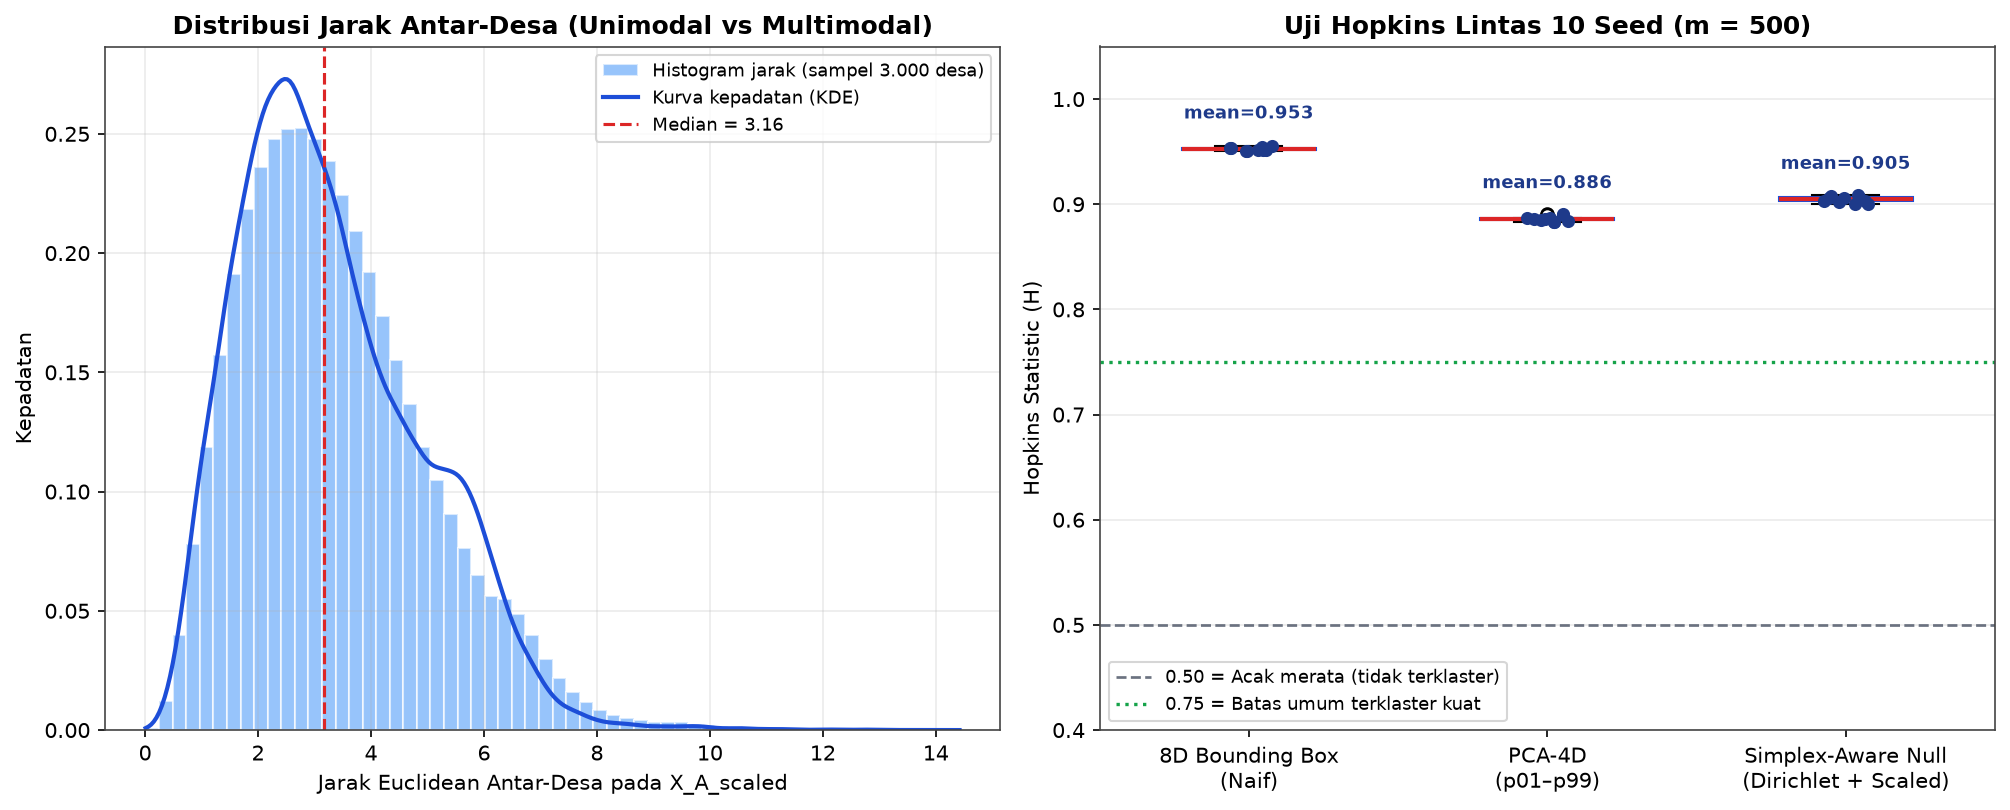

Saved: /Users/otnansirk/S2-MMI/DATA-SCIENCE/spatial-pertanahan-nasional/modeling/outputs/step1_summary.json


In [6]:
# 1.5 Uji Cluster Tendency: Hopkins 3 Versi (10 seed, m=500) & Distribusi Jarak
def compute_hopkins_from_samples(x_real_all, x_real_sample, x_synth):
    nn_real = NearestNeighbors(n_neighbors=2, metric="euclidean").fit(x_real_all)
    w_dists, _ = nn_real.kneighbors(x_real_sample)
    w = w_dists[:, 1]
    nn_synth = NearestNeighbors(n_neighbors=1, metric="euclidean").fit(x_real_all)
    u_dists, _ = nn_synth.kneighbors(x_synth)
    u = u_dists[:, 0]
    denom = float(np.sum(u) + np.sum(w))
    return float(np.sum(u) / denom) if denom > 0 else float("nan")

x_arr = x_a_scaled.to_numpy()
pca4_arr = pca_scores[:, :4]
mins_8d, maxs_8d = x_arr.min(axis=0), x_arr.max(axis=0)
p01_pc4, p99_pc4 = np.quantile(pca4_arr, 0.01, axis=0), np.quantile(pca4_arr, 0.99, axis=0)
dens_p01, dens_p99 = x_a["log_parcel_density"].quantile([0.01, 0.99]).to_numpy()
size_p01, size_p99 = x_a["log_mean_parcel"].quantile([0.01, 0.99]).to_numpy()

comp_centers = np.array([sc_a["comp_center"][c] for c in sc_a["comp_cols"]])
comp_factor = float(sc_a["comp_factor"])
dens_center, dens_scale = float(sc_a["center"]["log_parcel_density"]), float(sc_a["scale"]["log_parcel_density"])
size_center, size_scale = float(sc_a["center"]["log_mean_parcel"]), float(sc_a["scale"]["log_mean_parcel"])

hopkins_8d, hopkins_pca4, hopkins_simplex = [], [], []
m = 500
for seed in range(42, 52):
    rng_s = np.random.default_rng(seed)
    idx = rng_s.choice(len(x_arr), size=m, replace=False)
    hopkins_8d.append(compute_hopkins_from_samples(x_arr, x_arr[idx], rng_s.uniform(mins_8d, maxs_8d, size=(m, x_arr.shape[1]))))
    hopkins_pca4.append(compute_hopkins_from_samples(pca4_arr, pca4_arr[idx], rng_s.uniform(p01_pc4, p99_pc4, size=(m, 4))))
    s_comp_scaled = (np.sqrt(rng_s.dirichlet(np.ones(6), size=m)) - comp_centers) * comp_factor
    s_dens = (rng_s.uniform(dens_p01, dens_p99, size=(m, 1)) - dens_center) / dens_scale
    s_size = (rng_s.uniform(size_p01, size_p99, size=(m, 1)) - size_center) / size_scale
    hopkins_simplex.append(compute_hopkins_from_samples(x_arr, x_arr[idx], np.hstack([s_comp_scaled, s_dens, s_size])))

rng42 = np.random.default_rng(42)
pairwise_dists = pdist(x_arr[rng42.choice(len(x_arr), size=3000, replace=False)], metric="euclidean")
nn10 = NearestNeighbors(n_neighbors=11, metric="euclidean").fit(x_arr)
d10, _ = nn10.kneighbors(x_arr[rng42.choice(len(x_arr), size=10000, replace=False)])
knn10_dists = d10[:, 10]

hopkins_table = pd.DataFrame([
    {"Metode": "8D Bounding Box (naif)", "Mean": np.mean(hopkins_8d), "SD": np.std(hopkins_8d, ddof=1), "Min": np.min(hopkins_8d), "Max": np.max(hopkins_8d)},
    {"Metode": "PCA-4D (p01-p99)", "Mean": np.mean(hopkins_pca4), "SD": np.std(hopkins_pca4, ddof=1), "Min": np.min(hopkins_pca4), "Max": np.max(hopkins_pca4)},
    {"Metode": "Simplex-Aware Null (Dirichlet)", "Mean": np.mean(hopkins_simplex), "SD": np.std(hopkins_simplex, ddof=1), "Min": np.min(hopkins_simplex), "Max": np.max(hopkins_simplex)},
]).round(4)
display(hopkins_table)
print(f"Pairwise distance (n=3,000) median={np.median(pairwise_dists):.2f}, p10={np.quantile(pairwise_dists, 0.1):.2f}, p90={np.quantile(pairwise_dists, 0.9):.2f}")
print(f"10-NN distance (n=10,000)   median={np.median(knn10_dists):.3f}, p10={np.quantile(knn10_dists, 0.1):.3f}, p90={np.quantile(knn10_dists, 0.9):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.5), dpi=150)
ax0 = axes[0]
ax0.hist(pairwise_dists, bins=60, density=True, color="#60a5fa", alpha=0.65, edgecolor="white", label="Histogram jarak (sampel 3.000 desa)")
kde = gaussian_kde(pairwise_dists[:100000])
xs = np.linspace(pairwise_dists.min(), pairwise_dists.max(), 300)
ax0.plot(xs, kde(xs), color="#1d4ed8", lw=2, label="Kurva kepadatan (KDE)")
med_d = float(np.median(pairwise_dists))
ax0.axvline(med_d, color="#dc2626", ls="--", lw=1.5, label=f"Median = {med_d:.2f}")
ax0.set_xlabel("Jarak Euclidean Antar-Desa pada X_A_scaled")
ax0.set_ylabel("Kepadatan")
ax0.set_title("Distribusi Jarak Antar-Desa (Unimodal vs Multimodal)", fontweight="bold")
ax0.legend(frameon=True, fontsize=8.5)
ax0.grid(alpha=0.25)

ax1 = axes[1]
methods = [
    ("8D Bounding Box\n(Naif)", hopkins_8d),
    ("PCA-4D\n(p01–p99)", hopkins_pca4),
    ("Simplex-Aware Null\n(Dirichlet + Scaled)", hopkins_simplex),
]
positions = [1, 2, 3]
ax1.boxplot([v for _, v in methods], positions=positions, widths=0.45, patch_artist=True,
            boxprops=dict(facecolor="#dbeafe", color="#1d4ed8"), medianprops=dict(color="#dc2626", linewidth=2))
rng_plot = np.random.default_rng(42)
for pos, (_, vals) in zip(positions, methods):
    ax1.scatter(np.full(len(vals), pos) + rng_plot.uniform(-0.08, 0.08, size=len(vals)), vals, color="#1e3a8a", s=28, zorder=3)
    ax1.text(pos, float(np.mean(vals)) + 0.025, f"mean={np.mean(vals):.3f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#1e3a8a")
ax1.axhline(0.50, color="#6b7280", ls="--", lw=1.3, label="0.50 = Acak merata (tidak terklaster)")
ax1.axhline(0.75, color="#16a34a", ls=":", lw=1.6, label="0.75 = Batas umum terklaster kuat")
ax1.set_xticks(positions)
ax1.set_xticklabels([name for name, _ in methods])
ax1.set_ylim(0.40, 1.05)
ax1.set_ylabel("Hopkins Statistic (H)")
ax1.set_title("Uji Hopkins Lintas 10 Seed (m = 500)", fontweight="bold")
ax1.legend(loc="lower left", frameon=True, fontsize=8.5)
ax1.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

def summarize_arr(vals):
    arr = np.asarray(vals, dtype=float)
    return {"mean": float(arr.mean()), "std": float(arr.std(ddof=1)), "median": float(np.median(arr)),
            "min": float(arr.min()), "max": float(arr.max()), "p10": float(np.quantile(arr, 0.10)), "p90": float(np.quantile(arr, 0.90))}

summary = {
    "sanity": {
        "n_rows": int(x_a_scaled.shape[0]),
        "n_cols": int(x_a_scaled.shape[1]),
        "leading_zero_kode8_count": int(x_a_scaled.index.str.startswith("0").sum()),
        "max_recipe_rebuild_diff": max_rebuild_diff,
        "comp_variance": comp_var,
        "other_variance": other_var,
        "total_variance": total_var,
        "comp_variance_pct": float(100.0 * comp_var / total_var),
        "other_variance_pct": float(100.0 * other_var / total_var),
    },
    "context_breakdown": {
        "dominant_right_counts": {str(k): int(v) for k, v in dom_counts.items()},
        "dominant_right_pct": {str(k): float(v) for k, v in (dom_counts / len(meta_fit) * 100).round(2).items()},
        "tipe_counts": {str(k): int(v) for k, v in meta_fit["tipe"].value_counts().items()},
    },
    "examples": examples_json,
    "pca": {
        "explained_variance_ratio": [float(x) for x in pca.explained_variance_ratio_],
        "cumulative_variance_ratio": [float(x) for x in np.cumsum(pca.explained_variance_ratio_)],
    },
    "tendency": {
        "n_seeds": 10,
        "sample_m": m,
        "hopkins_8d_box": summarize_arr(hopkins_8d) | {"values": hopkins_8d},
        "hopkins_pca4_p01_p99": summarize_arr(hopkins_pca4) | {"values": hopkins_pca4},
        "hopkins_simplex_null": summarize_arr(hopkins_simplex) | {"values": hopkins_simplex},
        "pairwise_dist_3k": summarize_arr(pairwise_dists),
        "knn10_dist_10k": summarize_arr(knn10_dists),
    },
    "place_later_rows": int(len(place_later)),
}
with open(OUT_DIR / "step1_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print("Saved:", OUT_DIR / "step1_summary.json")

### Vonis Step 1
- **Hopkins jujur (PCA-4D `0,886`, Simplex-Aware `0,905`)** jauh di atas `0,75`: sebaran desa **tidak acak merata**, melainkan berkumpul di kantong-kantong kepadatan tertentu.
- **Namun peta PCA & distribusi jarak (unimodal)** menegaskan bentuknya berupa **kontinum SHM ↔ Kosong** dengan jembatan transisi padat + ekor kantong khusus (HGU, Hak Pakai di PC3, HGB).
- **Langkah berikutnya (Step 2):** Bandingkan **K-Means**, **GMM**, dan **HDBSCAN** untuk melihat bagaimana masing-masing membelah kontinum & kantong tersebut.

## Step 2: Adu "Mak Comblang" — Eksperimen Algoritma Clustering (K-Means, GMM, HDBSCAN) & Pilih $k$

Karena di Step 1 kita lihat sebaran desa berbentuk **spektrum kontinu dengan kantong-kantong padat**, kita adu tiga "mak comblang" dengan cara kerja yang berbeda:
- **K-Means:** Membagi ruang jarak Euclidean menjadi $k$ wilayah dengan batas tegas (cepat dan jadi *baseline* standar).
- **GMM (*Gaussian Mixture Model*):** Mengizinkan bentuk geng lonjong/elips dan memberi probabilitas keanggotaan (*soft assignment*), cocok untuk awan kontinu yang tumpang tindih.
- **HDBSCAN:** Berbasis kepadatan — mencari kelompok padat secara alami tanpa dipaksa jumlah $k$, dan menandai area transisi renggang sebagai *noise* (`-1`).

In [7]:
# 2.1 K-Means (k = 2..10)
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture

sil_idx = np.random.default_rng(42).choice(len(x_arr), size=10000, replace=False)

km_labels = {}
km_rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(x_arr)
    km_labels[k] = labels
    shares = pd.Series(labels).value_counts(normalize=True) * 100.0
    km_rows.append({
        "k": k,
        "inertia": float(km.inertia_),
        "silhouette_10k": float(silhouette_score(x_arr[sil_idx], labels[sil_idx])),
        "calinski_harabasz": float(calinski_harabasz_score(x_arr, labels)),
        "davies_bouldin": float(davies_bouldin_score(x_arr, labels)),
        "min_cluster_pct": float(shares.min()),
        "max_cluster_pct": float(shares.max()),
    })

km_metrics_df = pd.DataFrame(km_rows)
display(km_metrics_df.round({"inertia": 0, "silhouette_10k": 4, "calinski_harabasz": 1, "davies_bouldin": 4, "min_cluster_pct": 2, "max_cluster_pct": 2}))

,k,inertia,silhouette_10k,calinski_harabasz,davies_bouldin,min_cluster_pct,max_cluster_pct
0,2,399196.0,0.2935,30308.6,1.3890,43.79,56.21
1,3,324743.0,0.2953,27543.1,1.3331,11.22,44.52
2,4,269027.0,0.2757,27533.1,1.2338,6.00,36.21
3,5,230981.0,0.2942,27253.0,1.0600,3.58,35.61
4,6,203622.0,0.2700,26821.4,1.1144,3.44,29.20
5,7,186543.0,0.2580,25583.8,1.0825,3.39,23.57
6,8,172818.0,0.2442,24552.5,1.1413,3.31,20.10
7,9,159705.0,0.2526,24045.1,1.0875,3.05,19.67
8,10,151995.0,0.2392,22895.6,1.1230,2.19,18.44


In [8]:
# 2.2 Gaussian Mixture Model / GMM (k = 2..10)
gmm_labels = {}
gmm_maxprob = {}
gmm_rows = []

for k in range(2, 11):
    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        n_init=3,
        max_iter=200,
        reg_covar=1e-5,
        random_state=42,
    )
    gmm.fit(x_arr)
    labels = gmm.predict(x_arr)
    maxprob = gmm.predict_proba(x_arr).max(axis=1)
    gmm_labels[k] = labels
    gmm_maxprob[k] = maxprob
    shares = pd.Series(labels).value_counts(normalize=True) * 100.0
    gmm_rows.append({
        "k": k,
        "bic": float(gmm.bic(x_arr)),
        "aic": float(gmm.aic(x_arr)),
        "silhouette_10k": float(silhouette_score(x_arr[sil_idx], labels[sil_idx])),
        "calinski_harabasz": float(calinski_harabasz_score(x_arr, labels)),
        "davies_bouldin": float(davies_bouldin_score(x_arr, labels)),
        "mean_max_prob": float(maxprob.mean()),
        "uncertain_pct": float((maxprob < 0.80).mean() * 100.0),
        "min_cluster_pct": float(shares.min()),
        "max_cluster_pct": float(shares.max()),
        "converged": bool(gmm.converged_),
    })

gmm_metrics_df = pd.DataFrame(gmm_rows)
gmm_metrics_df["delta_bic"] = gmm_metrics_df["bic"] - gmm_metrics_df["bic"].min()
cols_order = [
    "k", "bic", "delta_bic", "aic", "silhouette_10k", "calinski_harabasz",
    "davies_bouldin", "mean_max_prob", "uncertain_pct", "min_cluster_pct", "max_cluster_pct", "converged",
]
gmm_metrics_df = gmm_metrics_df[cols_order]
display(gmm_metrics_df.round({
    "bic": 0, "delta_bic": 0, "aic": 0, "silhouette_10k": 4, "calinski_harabasz": 1,
    "davies_bouldin": 4, "mean_max_prob": 4, "uncertain_pct": 2, "min_cluster_pct": 2, "max_cluster_pct": 2,
}))

,k,bic,delta_bic,aic,silhouette_10k,calinski_harabasz,davies_bouldin,mean_max_prob,uncertain_pct,min_cluster_pct,max_cluster_pct,converged
0,2,463673.0,914430.0,462849.0,0.3421,9414.2,1.4182,0.9990,0.19,6.50,93.50,True
1,3,33983.0,484740.0,32742.0,0.0550,6318.3,3.3089,0.9940,1.09,6.29,47.76,True
2,4,-71323.0,379434.0,-72981.0,0.0754,12510.7,2.2691,0.9834,3.11,10.57,38.26,True
3,5,-182946.0,267812.0,-185020.0,0.0677,11223.4,2.0735,0.9729,5.04,6.16,34.12,True
4,6,-271768.0,178990.0,-274259.0,0.0429,11975.0,2.5360,0.9705,5.52,6.20,27.92,True
5,7,-320651.0,130107.0,-323559.0,0.0395,12084.5,2.1898,0.9671,6.34,6.17,23.99,True
6,8,-413914.0,36843.0,-417239.0,-0.0011,11061.5,3.1685,0.9631,7.26,6.16,17.45,True
7,9,-434034.0,16723.0,-437776.0,-0.0042,10345.8,3.1574,0.9569,8.28,5.83,17.72,True
8,10,-450757.0,0.0,-454916.0,-0.0179,9774.3,3.3701,0.9499,9.59,5.80,18.24,True


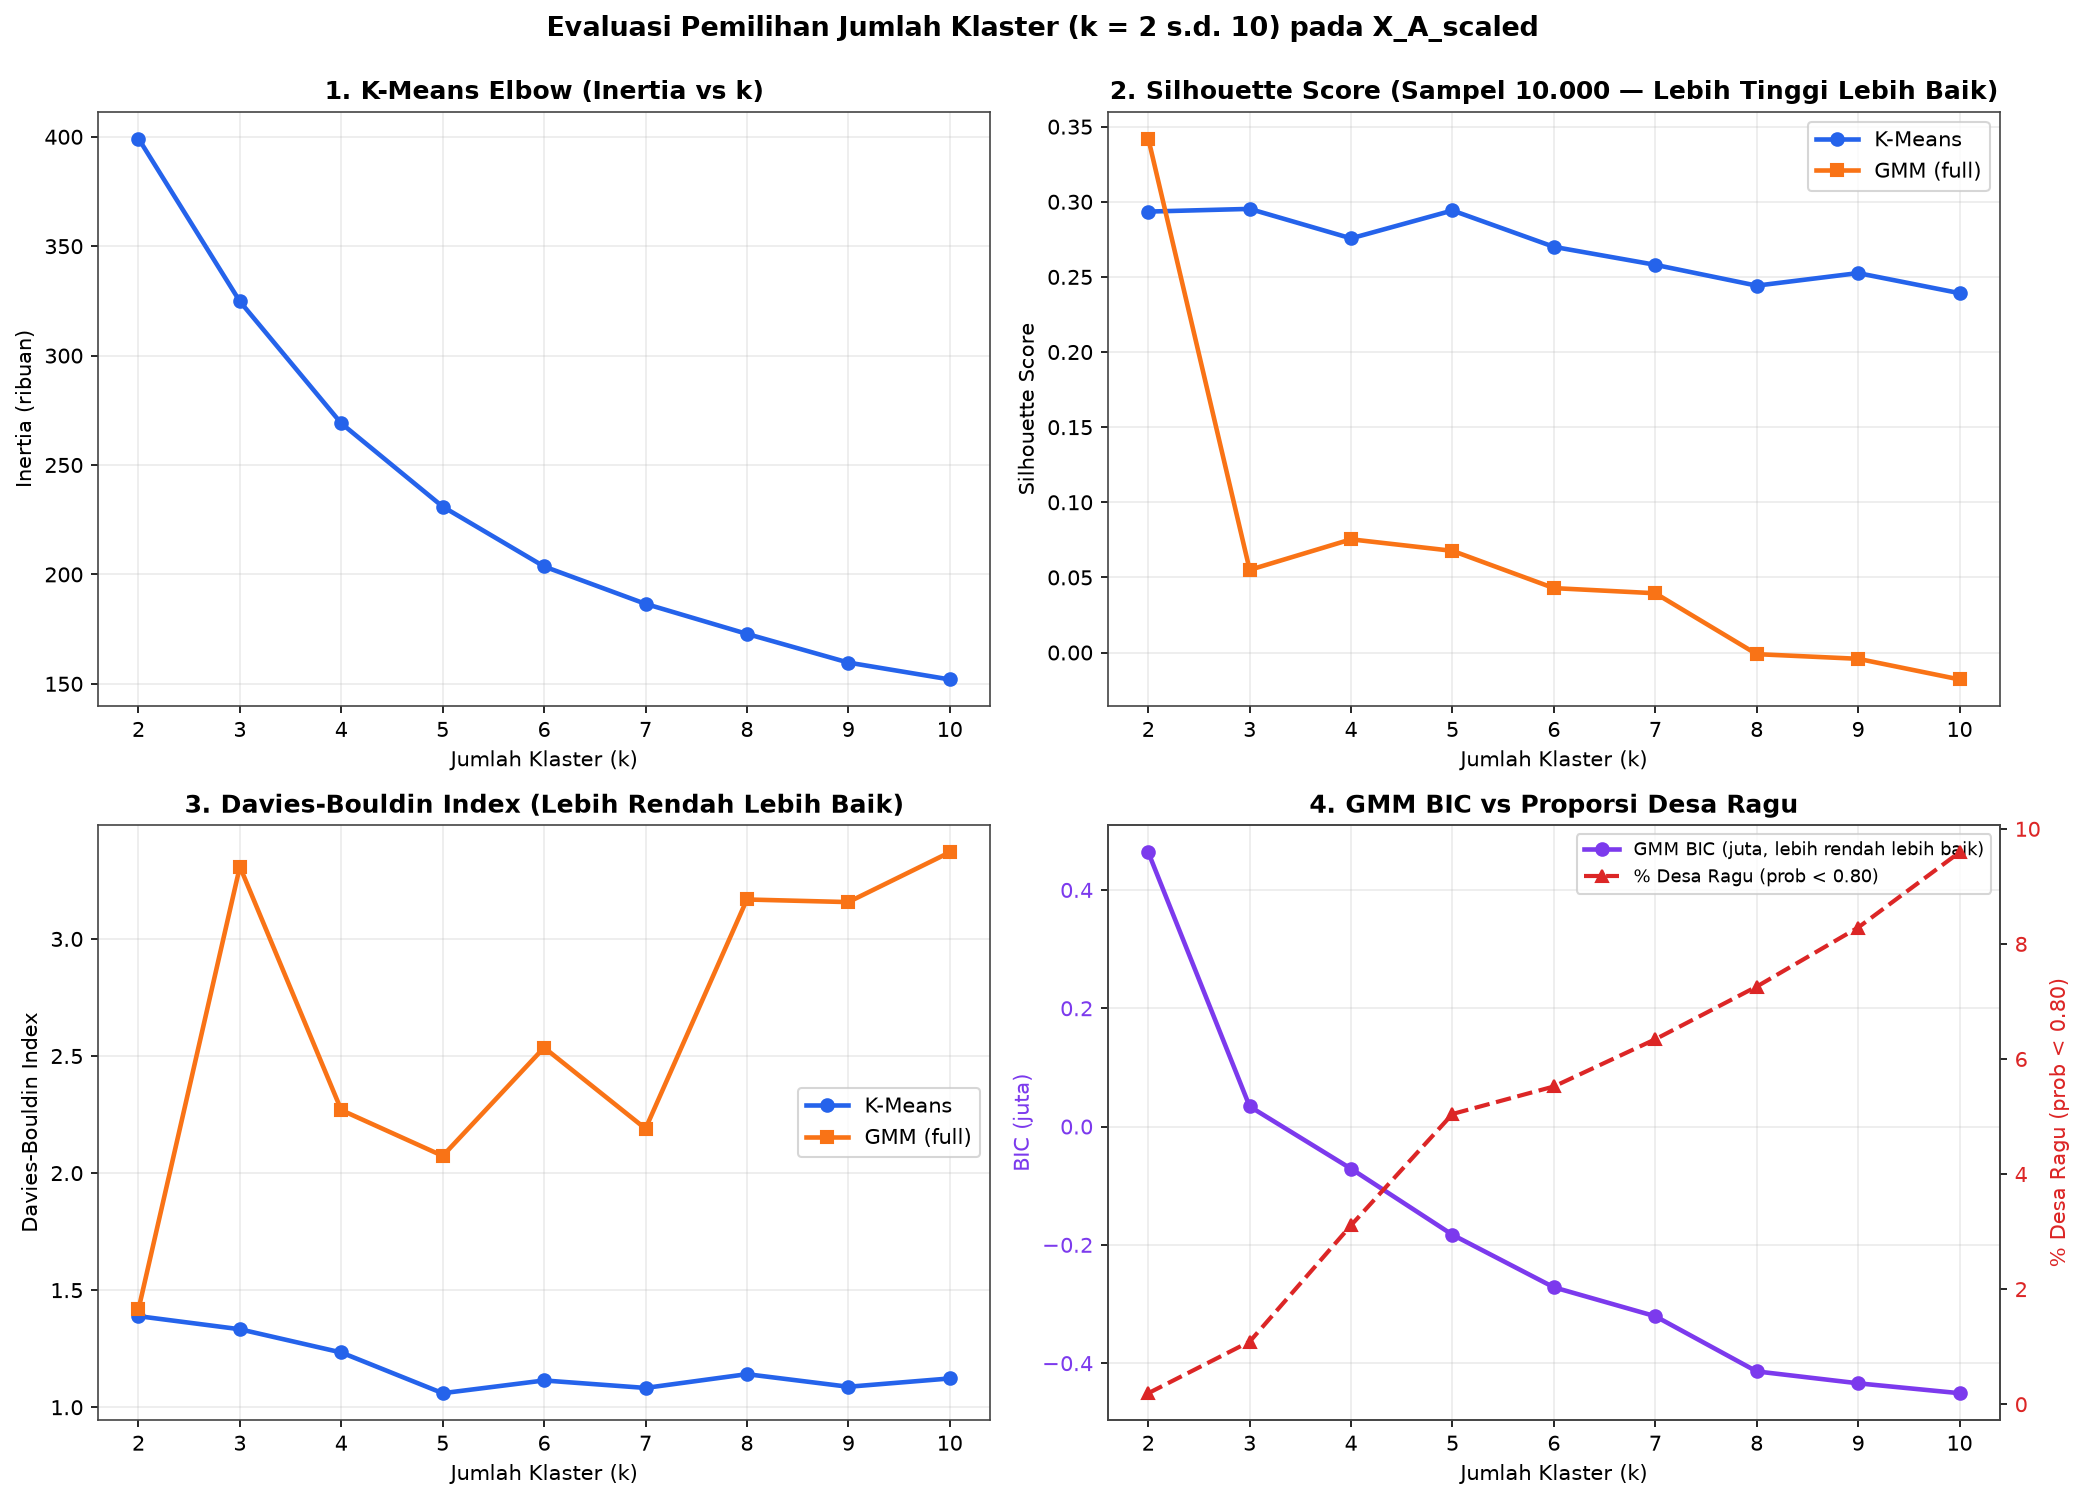

In [9]:
# 2.3 Grafik Perbandingan Metrik Pemilihan k (K-Means vs GMM)
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150)
ks = km_metrics_df["k"]

# Panel 1: K-Means Elbow
ax = axes[0, 0]
ax.plot(ks, km_metrics_df["inertia"] / 1000.0, marker="o", lw=2.2, color="#2563eb")
ax.set_title("1. K-Means Elbow (Inertia vs k)", fontweight="bold")
ax.set_xlabel("Jumlah Klaster (k)")
ax.set_ylabel("Inertia (ribuan)")
ax.set_xticks(ks)
ax.grid(alpha=0.25)

# Panel 2: Silhouette Score (10k sample)
ax = axes[0, 1]
ax.plot(ks, km_metrics_df["silhouette_10k"], marker="o", lw=2.2, color="#2563eb", label="K-Means")
ax.plot(ks, gmm_metrics_df["silhouette_10k"], marker="s", lw=2.2, color="#f97316", label="GMM (full)")
ax.set_title("2. Silhouette Score (Sampel 10.000 — Lebih Tinggi Lebih Baik)", fontweight="bold")
ax.set_xlabel("Jumlah Klaster (k)")
ax.set_ylabel("Silhouette Score")
ax.set_xticks(ks)
ax.legend(frameon=True)
ax.grid(alpha=0.25)

# Panel 3: Davies-Bouldin Index
ax = axes[1, 0]
ax.plot(ks, km_metrics_df["davies_bouldin"], marker="o", lw=2.2, color="#2563eb", label="K-Means")
ax.plot(ks, gmm_metrics_df["davies_bouldin"], marker="s", lw=2.2, color="#f97316", label="GMM (full)")
ax.set_title("3. Davies-Bouldin Index (Lebih Rendah Lebih Baik)", fontweight="bold")
ax.set_xlabel("Jumlah Klaster (k)")
ax.set_ylabel("Davies-Bouldin Index")
ax.set_xticks(ks)
ax.legend(frameon=True)
ax.grid(alpha=0.25)

# Panel 4: GMM BIC + % Desa Ragu (prob < 0.80)
ax = axes[1, 1]
l1 = ax.plot(ks, gmm_metrics_df["bic"] / 1e6, marker="o", lw=2.2, color="#7c3aed", label="GMM BIC (juta, lebih rendah lebih baik)")
ax.set_xlabel("Jumlah Klaster (k)")
ax.set_ylabel("BIC (juta)", color="#7c3aed")
ax.tick_params(axis="y", labelcolor="#7c3aed")
ax.set_xticks(ks)
ax.grid(alpha=0.25)

ax_r = ax.twinx()
l2 = ax_r.plot(ks, gmm_metrics_df["uncertain_pct"], marker="^", ls="--", lw=2.0, color="#dc2626", label="% Desa Ragu (prob < 0.80)")
ax_r.set_ylabel("% Desa Ragu (prob < 0.80)", color="#dc2626")
ax_r.tick_params(axis="y", labelcolor="#dc2626")
ax.set_title("4. GMM BIC vs Proporsi Desa Ragu", fontweight="bold")
lines = l1 + l2
ax.legend(lines, [l.get_label() for l in lines], loc="upper right", frameon=True, fontsize=8.5)

fig.suptitle("Evaluasi Pemilihan Jumlah Klaster (k = 2 s.d. 10) pada X_A_scaled", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
plt.show()

In [10]:
# 2.4 HDBSCAN Berbasis Kepadatan pada 77.770 desa
hdb_configs = [(250, 30), (500, 50), (1000, 50), (2000, 100)]
hdb_labels = {}
hdb_rows = []

for mcs, ms in hdb_configs:
    hdb = HDBSCAN(min_cluster_size=mcs, min_samples=ms, copy=False, n_jobs=-1)
    labels = hdb.fit_predict(x_arr)
    hdb_labels[(mcs, ms)] = labels
    non_noise_mask = labels != -1
    unique_clusters = sorted([c for c in set(labels) if c != -1])
    n_clusters = len(unique_clusters)
    noise_count = int((labels == -1).sum())
    noise_pct = float((labels == -1).mean() * 100.0)

    if n_clusters > 0:
        counts = pd.Series(labels[non_noise_mask]).value_counts() / len(labels) * 100.0
        largest_pct = float(counts.max())
        smallest_pct = float(counts.min())
    else:
        largest_pct, smallest_pct = 0.0, 0.0

    if n_clusters >= 2:
        nn_idx = np.flatnonzero(non_noise_mask)
        if len(nn_idx) > 10000:
            nn_idx = np.random.default_rng(42).choice(nn_idx, size=10000, replace=False)
        sil_nn = float(silhouette_score(x_arr[nn_idx], labels[nn_idx]))
    else:
        sil_nn = float("nan")

    hdb_rows.append({
        "min_cluster_size": mcs,
        "min_samples": ms,
        "n_clusters": n_clusters,
        "noise_count": noise_count,
        "noise_pct": noise_pct,
        "largest_cluster_pct": largest_pct,
        "smallest_cluster_pct": smallest_pct,
        "silhouette_non_noise_10k": sil_nn,
    })

hdb_metrics_df = pd.DataFrame(hdb_rows)
display(hdb_metrics_df.round({"noise_pct": 2, "largest_cluster_pct": 2, "smallest_cluster_pct": 2, "silhouette_non_noise_10k": 4}))

,min_cluster_size,min_samples,n_clusters,noise_count,noise_pct,largest_cluster_pct,smallest_cluster_pct,silhouette_non_noise_10k
0,250,30,3,16089,20.69,77.45,0.81,0.4927
1,500,50,3,15283,19.65,78.56,0.76,0.4871
2,1000,50,2,65897,84.73,12.11,3.16,0.5713
3,2000,100,0,77770,100.00,0.00,0.00,NaN


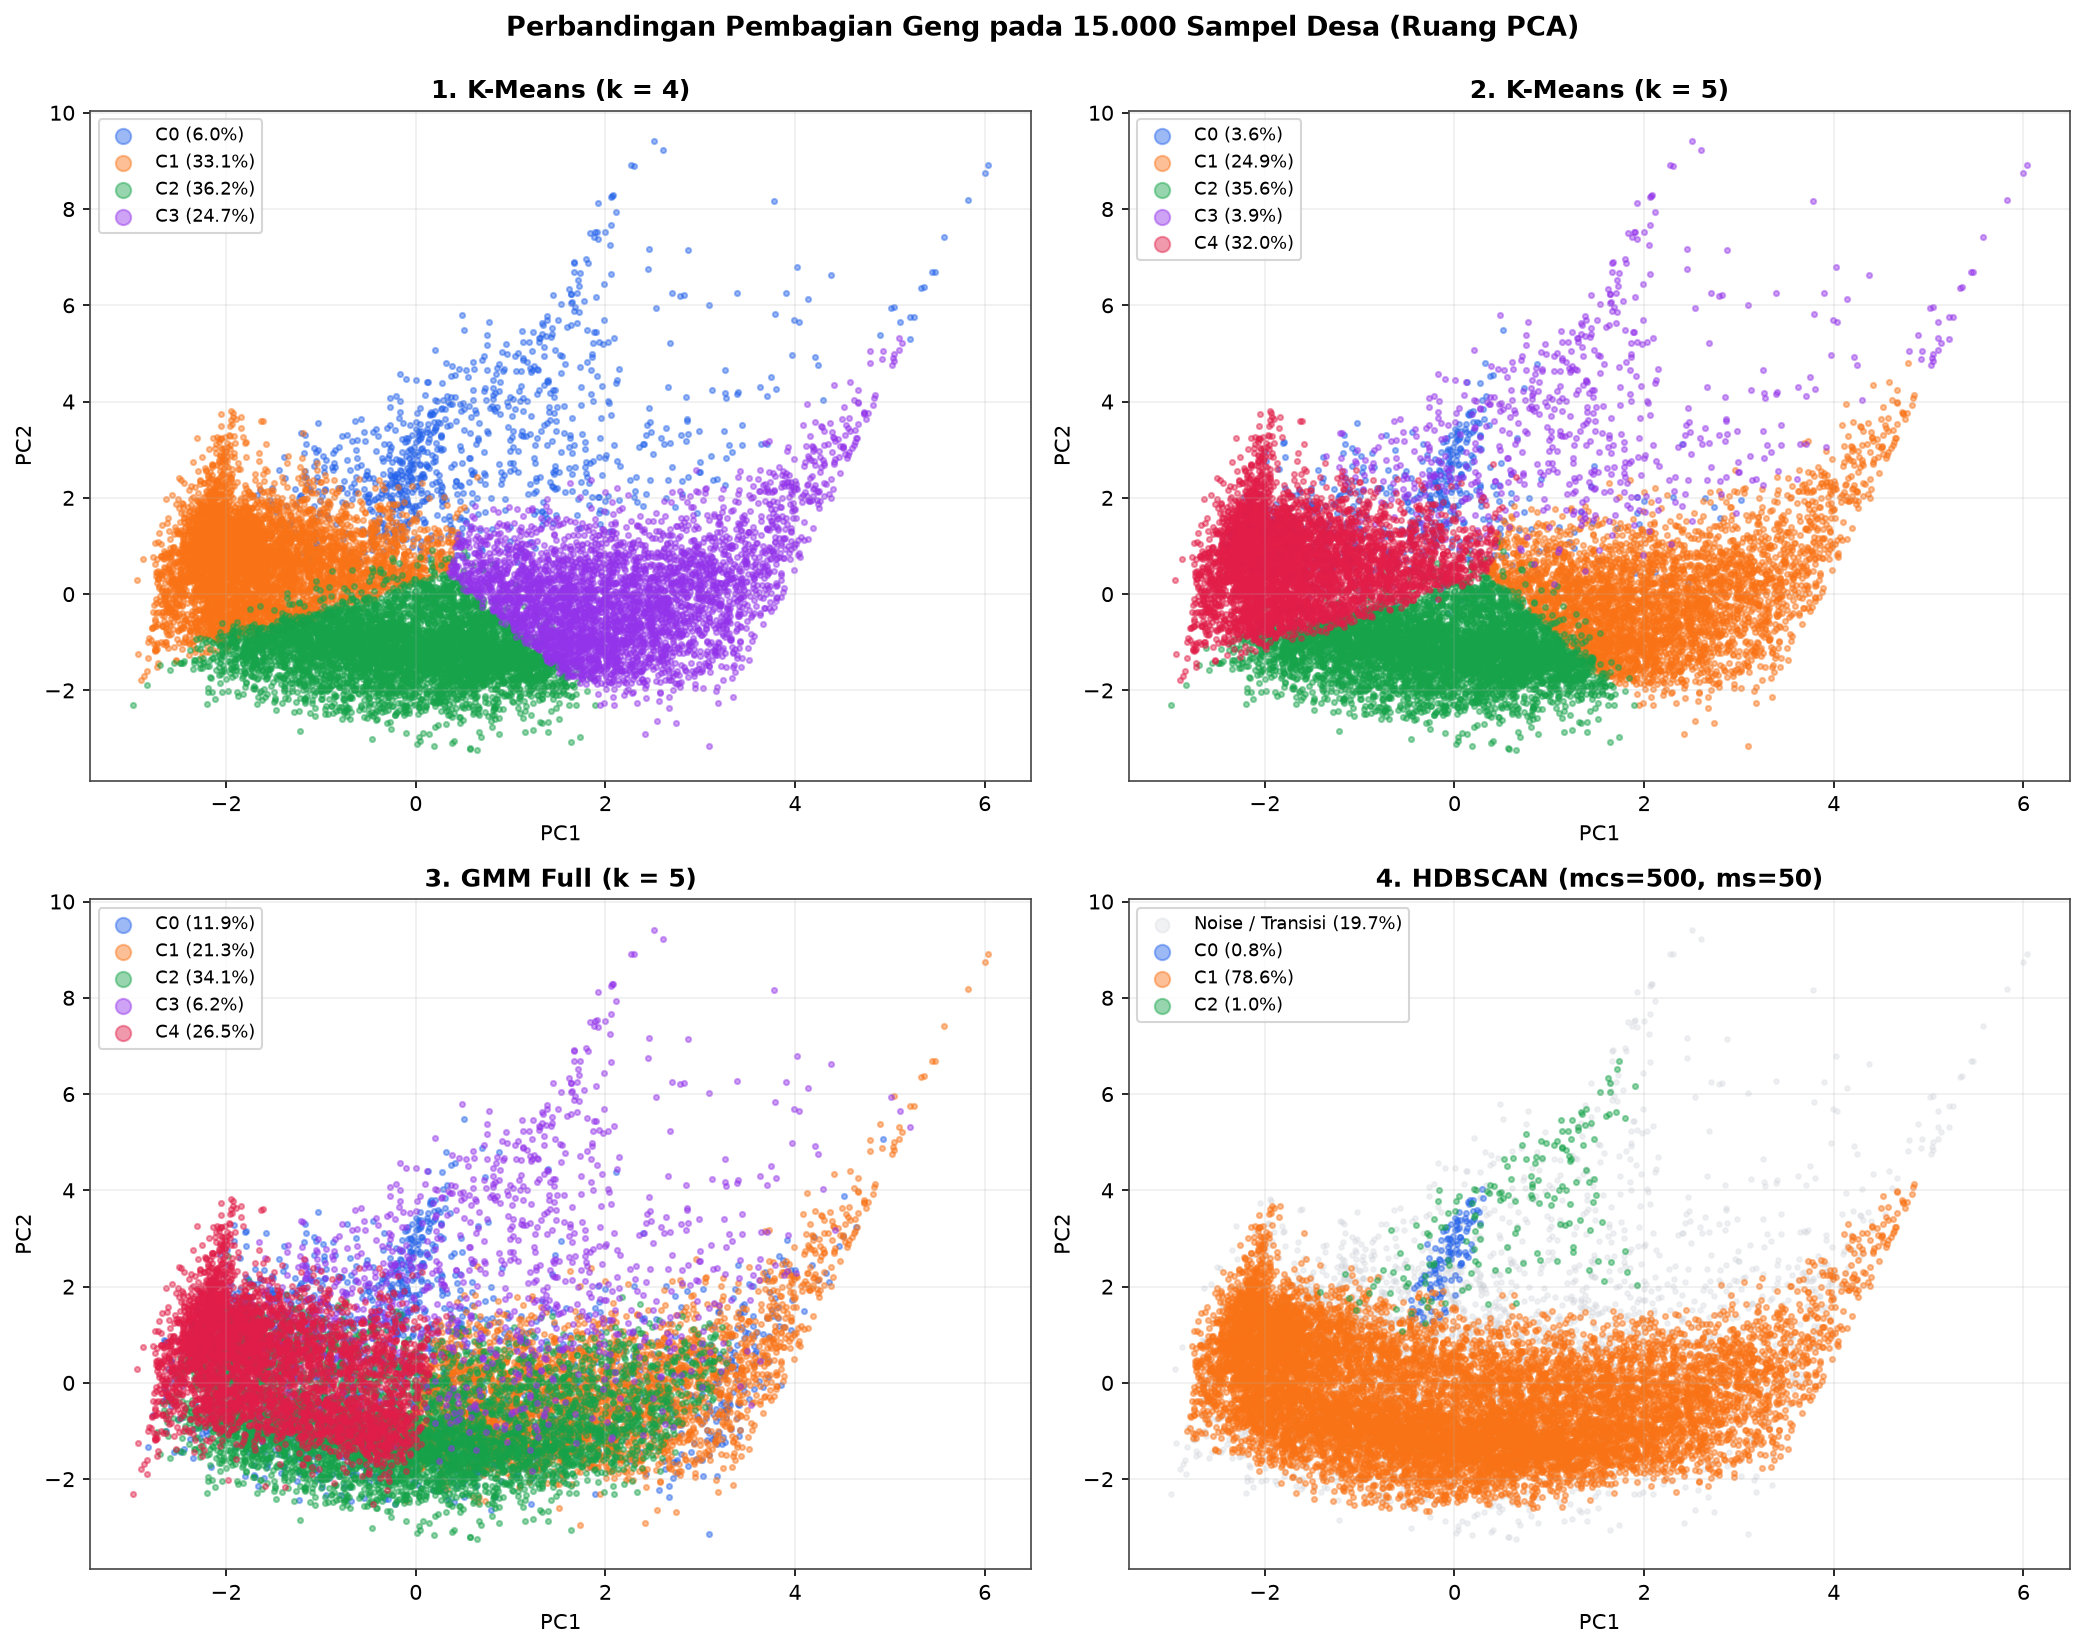

Adjusted Rand Index (ARI) Antar-Model (semua 77.770 desa):


,KM_k3,KM_k4,KM_k5,KM_k6,GMM_k4,GMM_k5,GMM_k6,HDB_500
KM_k3,1.000,0.439,0.415,0.450,0.151,0.234,0.224,0.106
KM_k4,0.439,1.000,0.941,0.510,0.244,0.249,0.241,0.074
KM_k5,0.415,0.941,1.000,0.535,0.240,0.265,0.257,0.089
KM_k6,0.450,0.510,0.535,1.000,0.190,0.251,0.287,0.077
GMM_k4,0.151,0.244,0.240,0.190,1.000,0.579,0.523,0.132
GMM_k5,0.234,0.249,0.265,0.251,0.579,1.000,0.600,0.164
GMM_k6,0.224,0.241,0.257,0.287,0.523,0.600,1.000,0.130
HDB_500,0.106,0.074,0.089,0.077,0.132,0.164,0.130,1.000


ARI vs HDB_500 khusus desa non-noise: {'KM_k3': 0.056, 'KM_k4': 0.041, 'KM_k5': 0.041, 'KM_k6': 0.031, 'GMM_k4': 0.047, 'GMM_k5': 0.038, 'GMM_k6': 0.028}

--- Quick Profile: K-Means (k=4) ---


,n_desa,pct,med_SHM%,med_Kosong%,med_HGU%,med_Pakai%,med_HGB%,med_persil,Kelurahan%
cluster,,,,,,,,,
0,4667,6.00,5.4,1.6,41.8,0.5,0.0,117,13.2
1,25770,33.14,91.9,2.2,0.0,0.9,0.0,352,13.7
2,28161,36.21,57.4,31.1,0.0,3.9,0.1,2072,28.7
3,19172,24.65,19.3,77.2,0.0,0.3,0.0,758,16.6



--- Quick Profile: K-Means (k=5) ---


,n_desa,pct,med_SHM%,med_Kosong%,med_HGU%,med_Pakai%,med_HGB%,med_persil,Kelurahan%
cluster,,,,,,,,,
0,2786,3.58,9.6,0.0,0.0,70.8,0.0,9,14.2
1,19360,24.89,19.7,76.9,0.0,0.3,0.0,768,16.8
2,27696,35.61,58.0,30.8,0.0,4.0,0.1,2088,28.7
3,3068,3.94,10.4,7.3,64.2,0.1,0.0,482,14.4
4,24860,31.97,92.4,2.3,0.0,0.8,0.0,368,13.5


... (5 outputs left out)

,n_desa,pct,med_SHM%,med_Kosong%,med_HGU%,med_Pakai%,med_HGB%,med_persil,Kelurahan%
cluster,,,,,,,,,
0,9292,11.95,31.5,8.6,0.0,7.9,0.3,184,26.9
1,16582,21.32,30.2,68.4,0.0,0.3,0.0,784,11.6
2,26537,34.12,59.4,29.5,0.0,2.5,0.4,1783,30.6
3,4787,6.16,22.6,12.9,41.1,0.2,0.0,850,15.0
4,20572,26.45,90.8,4.2,0.0,0.9,0.0,400,10.5



--- Quick Profile: HDBSCAN (mcs=500, ms=50) ---


,n_desa,pct,med_SHM%,med_Kosong%,med_HGU%,med_Pakai%,med_HGB%,med_persil,Kelurahan%
cluster,,,,,,,,,
-1,15283,19.65,35.5,14.3,0.0,2.6,0.1,324,25.9
0,589,0.76,0.0,0.0,0.0,100.0,0.0,2,4.8
1,61094,78.56,64.3,28.1,0.0,1.1,0.0,1000,18.5
2,804,1.03,16.8,1.6,77.3,0.1,0.0,608,12.9


Saved: /Users/otnansirk/S2-MMI/DATA-SCIENCE/spatial-pertanahan-nasional/modeling/outputs/step2_summary.json


In [11]:
# 2.5 Adu Visual di Ruang PCA, ARI Antar-Algoritma & Intipan Profil Awal
fig, axes = plt.subplots(2, 2, figsize=(14, 11), dpi=150)
cmap_clusters = ["#2563eb", "#f97316", "#16a34a", "#9333ea", "#e11d48", "#0891b2", "#ca8a04"]

panels = [
    ("1. K-Means (k = 4)", km_labels[4], False),
    ("2. K-Means (k = 5)", km_labels[5], False),
    ("3. GMM Full (k = 5)", gmm_labels[5], False),
    ("4. HDBSCAN (mcs=500, ms=50)", hdb_labels[(500, 50)], True),
]

for ax, (title, full_labels, is_hdb) in zip(axes.flat, panels):
    s_lbl = full_labels[sample_pos]
    if is_hdb:
        m_noise = s_lbl == -1
        ax.scatter(
            pc1_s[m_noise], pc2_s[m_noise], s=5, alpha=0.30, color="#d1d5db",
            label=f"Noise / Transisi ({(full_labels == -1).mean()*100:.1f}%)", rasterized=True,
        )
    uniq = sorted([c for c in np.unique(full_labels) if c != -1])
    for idx_c, cid in enumerate(uniq):
        m_c = s_lbl == cid
        pct_full = (full_labels == cid).mean() * 100.0
        ax.scatter(
            pc1_s[m_c], pc2_s[m_c], s=6, alpha=0.45, color=cmap_clusters[idx_c % len(cmap_clusters)],
            label=f"C{cid} ({pct_full:.1f}%)", rasterized=True,
        )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(markerscale=3, fontsize=8.5, loc="upper left", frameon=True)
    ax.grid(alpha=0.2)

fig.suptitle("Perbandingan Pembagian Geng pada 15.000 Sampel Desa (Ruang PCA)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
plt.show()

# ARI antar-algoritma
models_compare = {
    "KM_k3": km_labels[3],
    "KM_k4": km_labels[4],
    "KM_k5": km_labels[5],
    "KM_k6": km_labels[6],
    "GMM_k4": gmm_labels[4],
    "GMM_k5": gmm_labels[5],
    "GMM_k6": gmm_labels[6],
    "HDB_500": hdb_labels[(500, 50)],
}
names = list(models_compare.keys())
ari_mat = pd.DataFrame(index=names, columns=names, dtype=float)
for n1 in names:
    for n2 in names:
        ari_mat.loc[n1, n2] = adjusted_rand_score(models_compare[n1], models_compare[n2])

hdb_nn_mask = hdb_labels[(500, 50)] != -1
ari_hdb_non_noise = {
    n: float(adjusted_rand_score(models_compare[n][hdb_nn_mask], hdb_labels[(500, 50)][hdb_nn_mask]))
    for n in names if n != "HDB_500"
}
print("Adjusted Rand Index (ARI) Antar-Model (semua 77.770 desa):")
display(ari_mat.round(3))
print("ARI vs HDB_500 khusus desa non-noise:", {k: round(v, 3) for k, v in ari_hdb_non_noise.items()})


def quick_profile(labels, name):
    df = meta_fit[[
        "tipe", "hak_milik_share_luas", "kosong_share_luas",
        "hgu_share_luas", "hak_pakai_share_luas", "hgb_share_luas", "jumlah_persil",
    ]].copy()
    df["cluster"] = labels
    df["is_kelurahan"] = (df["tipe"] == "Kelurahan").astype(float) * 100.0
    g = df.groupby("cluster")
    prof = pd.DataFrame({
        "n_desa": g.size(),
        "pct": (g.size() / len(df) * 100.0).round(2),
        "med_SHM%": (g["hak_milik_share_luas"].median() * 100.0).round(1),
        "med_Kosong%": (g["kosong_share_luas"].median() * 100.0).round(1),
        "med_HGU%": (g["hgu_share_luas"].median() * 100.0).round(1),
        "med_Pakai%": (g["hak_pakai_share_luas"].median() * 100.0).round(1),
        "med_HGB%": (g["hgb_share_luas"].median() * 100.0).round(1),
        "med_persil": g["jumlah_persil"].median().round(0).astype(int),
        "Kelurahan%": g["is_kelurahan"].mean().round(1),
    })
    print(f"\n--- Quick Profile: {name} ---")
    display(prof)
    return prof.reset_index().to_dict(orient="records")


profiles_summary = {
    "KM_k4": quick_profile(km_labels[4], "K-Means (k=4)"),
    "KM_k5": quick_profile(km_labels[5], "K-Means (k=5)"),
    "KM_k6": quick_profile(km_labels[6], "K-Means (k=6)"),
    "GMM_k4": quick_profile(gmm_labels[4], "GMM (k=4)"),
    "GMM_k5": quick_profile(gmm_labels[5], "GMM (k=5)"),
    "HDB_500": quick_profile(hdb_labels[(500, 50)], "HDBSCAN (mcs=500, ms=50)"),
}

step2_summary = {
    "kmeans_metrics": km_metrics_df.to_dict(orient="records"),
    "gmm_metrics": gmm_metrics_df.to_dict(orient="records"),
    "hdbscan_metrics": hdb_metrics_df.to_dict(orient="records"),
    "ari_matrix": ari_mat.round(4).to_dict(),
    "ari_vs_hdb500_non_noise": ari_hdb_non_noise,
    "quick_profiles": profiles_summary,
}
with open(OUT_DIR / "step2_summary.json", "w", encoding="utf-8") as f:
    json.dump(step2_summary, f, indent=2, ensure_ascii=False)
print("Saved:", OUT_DIR / "step2_summary.json")

### Vonis Step 2

- **HDBSCAN (`mcs=500, ms=50`)** mengonfirmasi realitas struktur data: spektrum SHM ↔ Campuran ↔ Kosong tersambung menjadi satu benua besar (`78,6%` desa), hanya kantong **HGU murni (`1,0%`)** dan **Hak Pakai ekstrem (`0,8%`)** yang terpisah secara kepadatan, sementara `19,7%` desa dianggap *noise*. HDBSCAN tidak cocok untuk segmentasi kebijakan penuh, tetapi membuktikan bahwa kantong HGU & Hak Pakai memang nyata.
- **GMM Full** justru mengalami penurunan kualitas di atas $k=2$: *Silhouette* anjlok ke `0,04–0,075` (negatif di $k \ge 8$) dan *Davies-Bouldin* naik ke `2,07–3,37` karena komponen elipsnya tumpang tindih pada kontinum simplex.
- **K-Means adalah kandidat terkuat**, dan **$k = 5$ (dengan $k = 4$ sebagai pembanding terdekat)** paling konsisten secara metrik maupun makna pertanahan:
  - Di $k=5$, *Silhouette* (`0,2942`) menyamai puncak $k=3$ (`0,2953`) dan **Davies-Bouldin mencapai titik terendah terbaik (`1,0600`)**.
  - Dibanding $k=4$ (`ARI = 0,941`), naik ke $k=5$ memisahkan kelompok spesial `6,0%` menjadi dua kantong yang sangat masuk akal: **HGU (`3,94%`, median HGU `64,2%`)** dan **Hak Pakai (`3,58%`, median Hak Pakai `70,8%`)**, berdampingan dengan **Matang SHM (`31,97%`)**, **Transisi/Urban-Padat (`35,61%`)**, dan **Dominan Kosong/Target PTSL (`24,89%`)**.

## Step 3: Tes Anti-Goyah — Uji Stabilitas & Sensitivitas

Sebelum kita kepo membongkar isi tiap geng di Step 4, kandidat utama **K-Means ($k = 5$)** (dan pembanding $k = 4, 6$) harus lolos **4 tes ketahanan**:
1. **Multi-Seed (10 kali acak awal):** Kalau komputer mulai dari titik acak berbeda, apakah hasil gengnya sama persis?
2. **Bootstrap Resampling (20 kali kocok ulang 77.770 desa):** Kalau komposisi sampel desa digoyang, desa mana yang kokoh dan desa mana yang rawan pindah geng di perbatasan?
3. **Variant A vs Variant B (`X_B_scaled.csv`):** Seberapa besar perubahan jika luas desa & usia sertifikat ikut dimasukkan sebagai input?
4. **Sensitivitas Bobot Blok Komposisi (Decision D11):** Seberapa sensitif hasil jika porsi bobot 6 hak tanah diubah dari default (`70,1%`) menjadi `50/50`, `Comp=1` (`31,9%`), atau `Z-score per kolom` (`75,0%`)?

In [12]:
# 3.1 Uji Stabilitas Multi-Seed & Bootstrap Resampling
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import normalized_mutual_info_score


def match_labels(ref_labels, cand_labels):
    """Sejajarkan ID klaster kandidat ke referensi dengan Hungarian matching."""
    ref = np.asarray(ref_labels)
    cand = np.asarray(cand_labels)
    ref_ids = np.sort(np.unique(ref))
    cand_ids = np.sort(np.unique(cand))
    cm = np.zeros((len(ref_ids), len(cand_ids)), dtype=np.int64)
    for i, r in enumerate(ref_ids):
        m_r = ref == r
        for j, c in enumerate(cand_ids):
            cm[i, j] = int(np.sum(m_r & (cand == c)))
    row_ind, col_ind = linear_sum_assignment(-cm)
    mapping = {}
    jaccards = {}
    row_sums = cm.sum(axis=1)
    col_sums = cm.sum(axis=0)
    for r_idx, c_idx in zip(row_ind, col_ind):
        r_id = int(ref_ids[r_idx])
        c_id = int(cand_ids[c_idx])
        mapping[c_id] = r_id
        inter = cm[r_idx, c_idx]
        union = row_sums[r_idx] + col_sums[c_idx] - inter
        jaccards[r_id] = float(inter / union) if union > 0 else 0.0
    remapped = np.array([mapping[int(c)] for c in cand], dtype=ref.dtype)
    return remapped, jaccards


# Tag deskriptif dinamis untuk K-Means k=5
def build_k5_tags(labels):
    df_tmp = meta_fit[[
        "hak_milik_share_luas", "kosong_share_luas", "hgu_share_luas", "hak_pakai_share_luas"
    ]].copy()
    df_tmp["c"] = labels
    med = df_tmp.groupby("c").median() * 100.0
    tags = {}
    for cid, row in med.iterrows():
        if row["hgu_share_luas"] >= 40:
            tag = "Perkebunan HGU"
        elif row["hak_pakai_share_luas"] >= 40:
            tag = "Hak Pakai (Pem/Fasum)"
        elif row["kosong_share_luas"] >= 60:
            tag = "Dominan Kosong"
        elif row["hak_milik_share_luas"] >= 80:
            tag = "Matang SHM"
        else:
            tag = "Transisi / Padat"
        tags[int(cid)] = f"C{int(cid)}: {tag}"
    return tags


k5_tags = build_k5_tags(km_labels[5])
print("Label ringkas KM_k5:", k5_tags)

# Test A: Multi-Seed (10 seeds: 0..9)
seed_rows = []
multi_seed_summary = {}
for k in [4, 5, 6]:
    runs = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(x_arr) for s in range(10)]
    pair_aris = [
        adjusted_rand_score(runs[i], runs[j])
        for i in range(10)
        for j in range(i + 1, 10)
    ]
    row = {
        "k": k,
        "n_pairs": len(pair_aris),
        "ari_mean": float(np.mean(pair_aris)),
        "ari_std": float(np.std(pair_aris, ddof=1)),
        "ari_min": float(np.min(pair_aris)),
        "ari_max": float(np.max(pair_aris)),
    }
    seed_rows.append(row)
    multi_seed_summary[f"k{k}"] = row

print("\nTest A — Multi-Seed Stability (10 seeds, 45 pasang):")
display(pd.DataFrame(seed_rows).round(5))

# Test B: Bootstrap Resampling (20 resamples)
boot_rows = []
boot_summary = {}
boot_aris_by_k = {}
k5_jaccards_all = {int(c): [] for c in sorted(np.unique(km_labels[5]))}
k5_agree_counts = np.zeros(len(x_arr), dtype=np.int32)

n_boot = 20
for k in [4, 5, 6]:
    ref_lbl = km_labels[k]
    aris = []
    nmis = []
    for b in range(n_boot):
        rng_b = np.random.default_rng(100 + b)
        b_idx = rng_b.choice(len(x_arr), size=len(x_arr), replace=True)
        km_b = KMeans(n_clusters=k, n_init=5, random_state=42 + b).fit(x_arr[b_idx])
        pred_full = km_b.predict(x_arr)
        aris.append(float(adjusted_rand_score(ref_lbl, pred_full)))
        nmis.append(float(normalized_mutual_info_score(ref_lbl, pred_full)))
        if k == 5:
            remapped, jacc = match_labels(ref_lbl, pred_full)
            for cid, jv in jacc.items():
                k5_jaccards_all[cid].append(jv)
            k5_agree_counts += (remapped == ref_lbl).astype(np.int32)
    boot_aris_by_k[k] = aris
    row = {
        "k": k,
        "boot_ari_mean": float(np.mean(aris)),
        "boot_ari_std": float(np.std(aris, ddof=1)),
        "boot_ari_min": float(np.min(aris)),
        "boot_ari_max": float(np.max(aris)),
        "boot_nmi_mean": float(np.mean(nmis)),
    }
    boot_rows.append(row)
    boot_summary[f"k{k}"] = row | {"values": aris}

print("\nTest B — Bootstrap Resampling (20 resamples):")
display(pd.DataFrame(boot_rows).round(4))

k5_jaccard_rows = []
per_cluster_jaccard_k5 = {}
for cid in sorted(k5_jaccards_all):
    vals = k5_jaccards_all[cid]
    rec = {
        "cluster": cid,
        "label": k5_tags[cid],
        "n_desa": int((km_labels[5] == cid).sum()),
        "jaccard_mean": float(np.mean(vals)),
        "jaccard_std": float(np.std(vals, ddof=1)),
        "jaccard_min": float(np.min(vals)),
    }
    k5_jaccard_rows.append(rec)
    per_cluster_jaccard_k5[str(cid)] = rec

village_agree_rate = k5_agree_counts / float(n_boot)
village_stability_k5 = {
    "mean_agreement": float(village_agree_rate.mean()),
    "pct_exact_100": float((village_agree_rate == 1.0).mean() * 100.0),
    "pct_ge_95": float((village_agree_rate >= 0.95).mean() * 100.0),
    "pct_lt_80_border": float((village_agree_rate < 0.80).mean() * 100.0),
    "count_lt_80_border": int((village_agree_rate < 0.80).sum()),
}
print("\nStabilitas per-klaster K-Means (k=5) di 20 Bootstrap:")
display(pd.DataFrame(k5_jaccard_rows).round(4))
print("Konsistensi per-desa (k=5):", {k: round(v, 3) if isinstance(v, float) else v for k, v in village_stability_k5.items()})

Label ringkas KM_k5: {0: 'C0: Hak Pakai (Pem/Fasum)', 1: 'C1: Dominan Kosong', 2: 'C2: Transisi / Padat', 3: 'C3: Perkebunan HGU', 4: 'C4: Matang SHM'}



Test A — Multi-Seed Stability (10 seeds, 45 pasang):


,k,n_pairs,ari_mean,ari_std,ari_min,ari_max
0,4,45,0.99082,0.00600,0.97576,0.99958
1,5,45,0.98904,0.00945,0.97220,0.99998
2,6,45,0.98092,0.01162,0.96349,0.99945



Test B — Bootstrap Resampling (20 resamples):


,k,boot_ari_mean,boot_ari_std,boot_ari_min,boot_ari_max,boot_nmi_mean
0,4,0.9771,0.0117,0.9554,0.9939,0.9636
1,5,0.9847,0.0073,0.9735,0.9959,0.9747
2,6,0.9650,0.0180,0.9230,0.9900,0.9561



Stabilitas per-klaster K-Means (k=5) di 20 Bootstrap:


,cluster,label,n_desa,jaccard_mean,jaccard_std,jaccard_min
0,0,C0: Hak Pakai (Pem/Fasum),2786,0.9872,0.0058,0.9763
1,1,C1: Dominan Kosong,19360,0.9877,0.0071,0.9775
2,2,C2: Transisi / Padat,27696,0.9870,0.0067,0.9771
3,3,C3: Perkebunan HGU,3068,0.9897,0.0053,0.9790
4,4,C4: Matang SHM,24860,0.9928,0.0027,0.9881


Konsistensi per-desa (k=5): {'mean_agreement': 0.995, 'pct_exact_100': 97.808, 'pct_ge_95': 98.201, 'pct_lt_80_border': 1.184, 'count_lt_80_border': 921}


In [13]:
# 3.2 Uji Sensitivitas: Variant A vs Variant B & Bobot Blok Komposisi (Decision D11)
x_b_scaled = pd.read_csv(DATA_DIR / "X_B_scaled.csv", **read_opts)
assert x_b_scaled.shape == (77098, 10), f"Unexpected X_B_scaled shape: {x_b_scaled.shape}"
assert not x_b_scaled.isna().any().any() and np.isfinite(x_b_scaled.to_numpy()).all()
assert x_b_scaled.index.isin(x_a_scaled.index).all()

common_ids = x_b_scaled.index
pos_in_a = x_a_scaled.index.get_indexer(common_ids)
x_b_arr = x_b_scaled.to_numpy()

ab_rows = []
variant_a_vs_b = {}
kmb_labels = {}
for k in [4, 5, 6]:
    lbl_b = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(x_b_arr)
    kmb_labels[k] = lbl_b
    lbl_a_common = km_labels[k][pos_in_a]
    ari_ab = float(adjusted_rand_score(lbl_a_common, lbl_b))
    nmi_ab = float(normalized_mutual_info_score(lbl_a_common, lbl_b))
    rec = {"k": k, "n_common": int(len(common_ids)), "ari_A_vs_B": ari_ab, "nmi_A_vs_B": nmi_ab}
    ab_rows.append(rec)
    variant_a_vs_b[f"k{k}"] = rec

print("Test C — Variant A vs Variant B (pada 77.098 desa irisan):")
display(pd.DataFrame(ab_rows).round(4))

# Cross-tab A vs B untuk k=5 setelah Hungarian matching
lbl_a5_common = km_labels[5][pos_in_a]
lbl_b5_matched, b5_jacc = match_labels(lbl_a5_common, kmb_labels[5])
ct_ab_pct = pd.crosstab(
    pd.Series(lbl_a5_common, name="Variant A").map(k5_tags),
    pd.Series(lbl_b5_matched, name="Variant B (matched)").map(k5_tags),
    normalize="index",
) * 100.0
print("\nPeta perpindahan anggota Variant A -> Variant B (k=5, % baris):")
display(ct_ab_pct.round(1))

# Cek 672 desa B-only (punya persil, tapi tanpa tahun pendaftaran) di dalam KM_A_k5
b_only_ids = x_a_scaled.index.difference(x_b_scaled.index)
b_only_pos = x_a_scaled.index.get_indexer(b_only_ids)
b_only_counts = pd.Series(km_labels[5][b_only_pos]).map(k5_tags).value_counts()
b_only_df = pd.DataFrame({
    "n_desa": b_only_counts,
    "pct": (b_only_counts / len(b_only_ids) * 100.0).round(1),
})
print(f"\nSebaran {len(b_only_ids)} desa B-only (tanpa tahun registrasi) di klaster KM_A_k5:")
display(b_only_df)

# Test D: Alternatif Bobot Blok Komposisi (Decision D11)
scale_50_50 = float(np.sqrt(other_var / comp_var))
scale_comp_1 = float(np.sqrt(1.0 / comp_var))

x_w50 = x_a_scaled.copy()
x_w50[COMP_COLS] = x_w50[COMP_COLS] * scale_50_50

x_wc1 = x_a_scaled.copy()
x_wc1[COMP_COLS] = x_wc1[COMP_COLS] * scale_comp_1

x_wz = x_a_scaled / x_a_scaled.std(ddof=1)

weight_configs = [
    ("Weight 50/50 (Blocks Equal)", x_w50),
    ("Weight Z-score All (75% Comp)", x_wz),
    ("Weight Comp=1 (31.9% Comp)", x_wc1),
]

weight_rows = []
weight_sensitivity = {}
for w_name, df_w in weight_configs:
    arr_w = df_w.to_numpy()
    v_comp_w = float(df_w[COMP_COLS].var(ddof=1).sum())
    v_tot_w = float(df_w.var(ddof=1).sum())
    comp_share_pct = 100.0 * v_comp_w / v_tot_w
    lbl5_w = KMeans(n_clusters=5, n_init=10, random_state=42).fit_predict(arr_w)
    lbl4_w = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(arr_w)
    _, jacc5_w = match_labels(km_labels[5], lbl5_w)
    rec = {
        "skema": w_name,
        "comp_var_pct": round(comp_share_pct, 1),
        "ari_k5_vs_default": float(adjusted_rand_score(km_labels[5], lbl5_w)),
        "nmi_k5_vs_default": float(normalized_mutual_info_score(km_labels[5], lbl5_w)),
        "ari_k4_vs_default": float(adjusted_rand_score(km_labels[4], lbl4_w)),
        "min_jaccard_k5": float(min(jacc5_w.values())),
        "mean_jaccard_k5": float(np.mean(list(jacc5_w.values()))),
    }
    weight_rows.append(rec)
    weight_sensitivity[w_name] = rec | {"per_cluster_jaccard_k5": jacc5_w}

print("\nTest D — Sensitivitas Bobot Blok Komposisi (Decision D11):")
display(pd.DataFrame(weight_rows).round(4))

Test C — Variant A vs Variant B (pada 77.098 desa irisan):


,k,n_common,ari_A_vs_B,nmi_A_vs_B
0,4,77098,0.6149,0.6250
1,5,77098,0.6450,0.6689
2,6,77098,0.6363,0.6655



Peta perpindahan anggota Variant A -> Variant B (k=5, % baris):


Variant B (matched),C0: Hak Pakai (Pem/Fasum),C1: Dominan Kosong,C2: Transisi / Padat,C3: Perkebunan HGU,C4: Matang SHM
Variant A,,,,,
C0: Hak Pakai (Pem/Fasum),93.1,0.4,3.2,0.4,2.8
C1: Dominan Kosong,0.0,94.3,2.2,2.3,1.2
C2: Transisi / Padat,0.0,18.3,78.0,0.0,3.7
C3: Perkebunan HGU,0.1,0.5,0.2,98.4,0.8
C4: Matang SHM,0.1,0.6,12.7,0.1,86.5



Sebaran 672 desa B-only (tanpa tahun registrasi) di klaster KM_A_k5:


,n_desa,pct
C1: Dominan Kosong,604,89.9
C3: Perkebunan HGU,64,9.5
C4: Matang SHM,2,0.3
C0: Hak Pakai (Pem/Fasum),2,0.3



Test D — Sensitivitas Bobot Blok Komposisi (Decision D11):


,skema,comp_var_pct,ari_k5_vs_default,nmi_k5_vs_default,ari_k4_vs_default,min_jaccard_k5,mean_jaccard_k5
0,Weight 50/50 (Blocks Equal),50.0,0.6969,0.6772,0.6490,0.5477,0.7520
1,Weight Z-score All (75% Comp),75.0,0.6555,0.6583,0.5048,0.6912,0.7894
2,Weight Comp=1 (31.9% Comp),31.9,0.5337,0.5115,0.5023,0.3596,0.5682


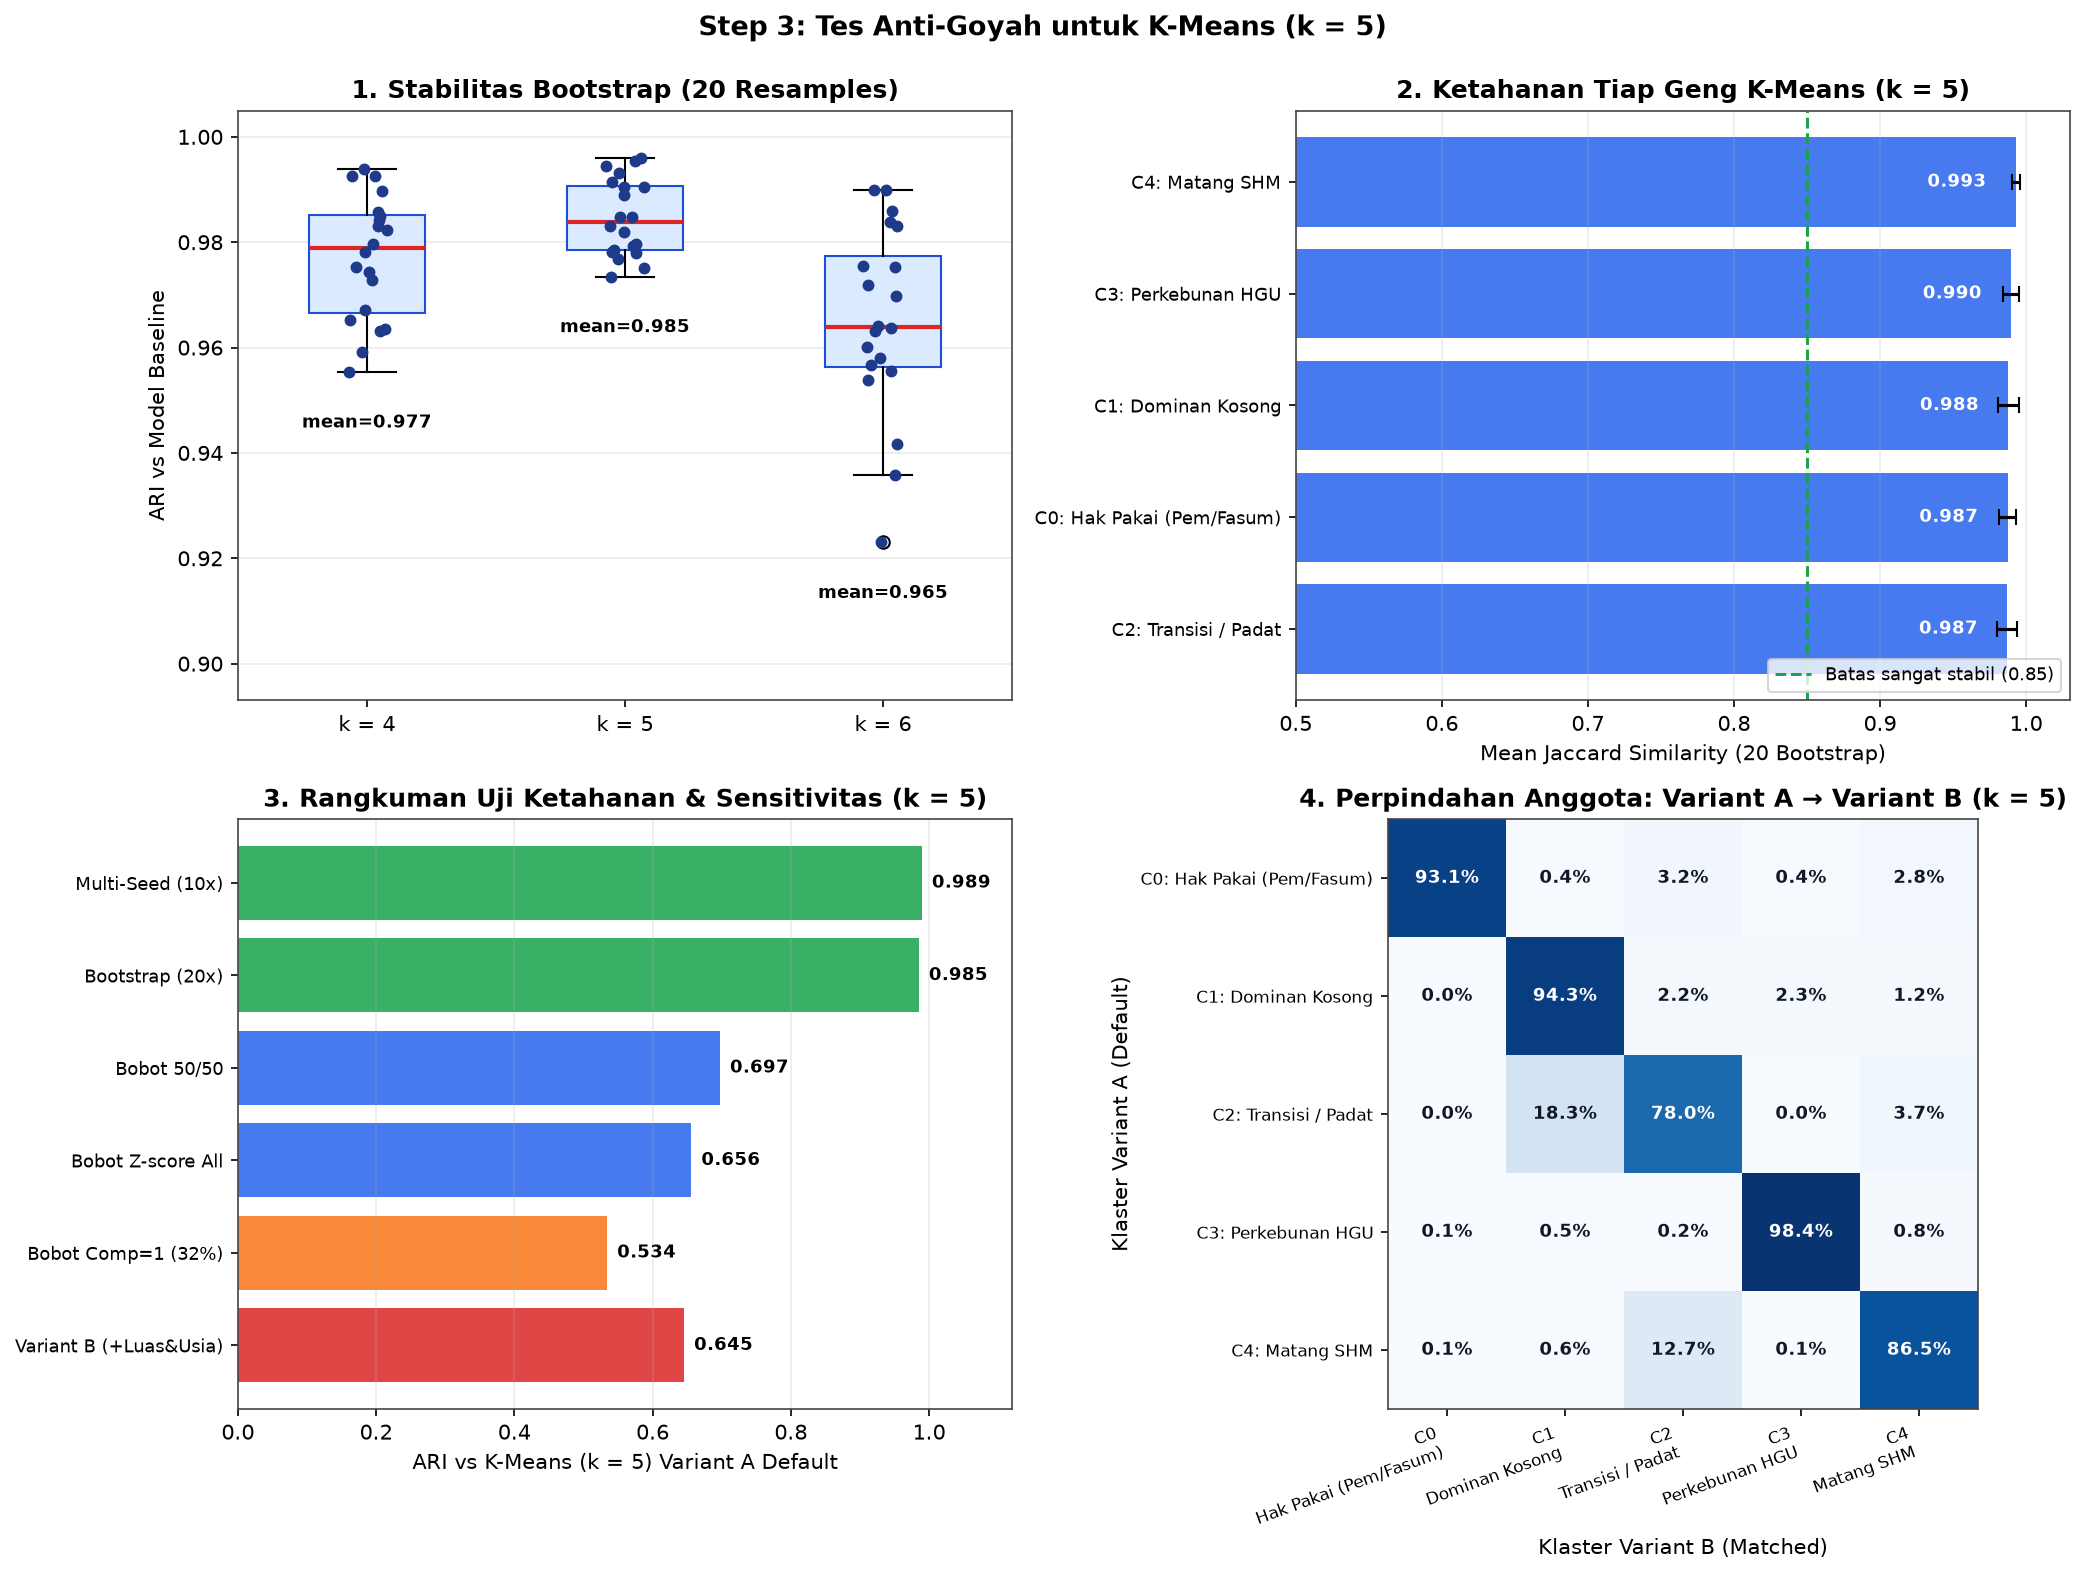

Saved: /Users/otnansirk/S2-MMI/DATA-SCIENCE/spatial-pertanahan-nasional/modeling/outputs/step3_summary.json


In [14]:
# 3.3 Visualisasi Stabilitas & Sensitivitas + Simpan step3_summary.json
fig, axes = plt.subplots(2, 2, figsize=(14, 10.5), dpi=150)

# Panel 1: Bootstrap ARI (k=4, 5, 6)
ax = axes[0, 0]
ks_boot = [4, 5, 6]
vals_boot = [boot_aris_by_k[k] for k in ks_boot]
ax.boxplot(
    vals_boot,
    positions=[1, 2, 3],
    widths=0.45,
    patch_artist=True,
    boxprops=dict(facecolor="#dbeafe", color="#1d4ed8"),
    medianprops=dict(color="#dc2626", linewidth=2),
)
rng_p = np.random.default_rng(42)
for pos, k, vals in zip([1, 2, 3], ks_boot, vals_boot):
    ax.scatter(np.full(len(vals), pos) + rng_p.uniform(-0.08, 0.08, size=len(vals)), vals, color="#1e3a8a", s=22, zorder=3)
    ax.text(pos, float(np.min(vals)) - 0.008, f"mean={np.mean(vals):.3f}", ha="center", va="top", fontsize=8.5, fontweight="bold")
ax.set_xticks([1, 2, 3])
ax.set_xticklabels([f"k = {k}" for k in ks_boot])
ax.set_ylim(min(min(v) for v in vals_boot) - 0.03, 1.005)
ax.set_ylabel("ARI vs Model Baseline")
ax.set_title("1. Stabilitas Bootstrap (20 Resamples)", fontweight="bold")
ax.grid(axis="y", alpha=0.25)

# Panel 2: Per-cluster Bootstrap Jaccard (k=5)
ax = axes[0, 1]
j_df = pd.DataFrame(k5_jaccard_rows).sort_values("jaccard_mean", ascending=True)
y_pos = np.arange(len(j_df))
bars = ax.barh(y_pos, j_df["jaccard_mean"], xerr=j_df["jaccard_std"], color="#2563eb", alpha=0.85, capsize=4)
for yp, (_, row) in zip(y_pos, j_df.iterrows()):
    ax.text(row["jaccard_mean"] - 0.02, yp, f"{row['jaccard_mean']:.3f}", va="center", ha="right", color="white", fontweight="bold", fontsize=8.5)
ax.axvline(0.85, color="#16a34a", ls="--", lw=1.4, label="Batas sangat stabil (0.85)")
ax.set_yticks(y_pos)
ax.set_yticklabels(j_df["label"], fontsize=8.5)
ax.set_xlim(0.50, 1.03)
ax.set_xlabel("Mean Jaccard Similarity (20 Bootstrap)")
ax.set_title("2. Ketahanan Tiap Geng K-Means (k = 5)", fontweight="bold")
ax.legend(loc="lower right", frameon=True, fontsize=8.5)
ax.grid(axis="x", alpha=0.25)

# Panel 3: Ringkasan ARI semua uji ketahanan (k=5)
ax = axes[1, 0]
stress_items = [
    ("Multi-Seed (10x)", multi_seed_summary["k5"]["ari_mean"], "#16a34a"),
    ("Bootstrap (20x)", boot_summary["k5"]["boot_ari_mean"], "#16a34a"),
    ("Bobot 50/50", weight_sensitivity["Weight 50/50 (Blocks Equal)"]["ari_k5_vs_default"], "#2563eb"),
    ("Bobot Z-score All", weight_sensitivity["Weight Z-score All (75% Comp)"]["ari_k5_vs_default"], "#2563eb"),
    ("Bobot Comp=1 (32%)", weight_sensitivity["Weight Comp=1 (31.9% Comp)"]["ari_k5_vs_default"], "#f97316"),
    ("Variant B (+Luas&Usia)", variant_a_vs_b["k5"]["ari_A_vs_B"], "#dc2626"),
]
s_labels = [x[0] for x in stress_items][::-1]
s_vals = [x[1] for x in stress_items][::-1]
s_cols = [x[2] for x in stress_items][::-1]
y_s = np.arange(len(stress_items))
ax.barh(y_s, s_vals, color=s_cols, alpha=0.85)
for yp, val in zip(y_s, s_vals):
    ax.text(val + 0.015, yp, f"{val:.3f}", va="center", ha="left", fontsize=8.5, fontweight="bold")
ax.set_yticks(y_s)
ax.set_yticklabels(s_labels, fontsize=8.5)
ax.set_xlim(0, 1.12)
ax.set_xlabel("ARI vs K-Means (k = 5) Variant A Default")
ax.set_title("3. Rangkuman Uji Ketahanan & Sensitivitas (k = 5)", fontweight="bold")
ax.grid(axis="x", alpha=0.25)

# Panel 4: Heatmap Cross-Tab A vs B (k=5)
ax = axes[1, 1]
mat = ct_ab_pct.to_numpy()
im = ax.imshow(mat, cmap="Blues", vmin=0, vmax=100)
short_labels = [k5_tags[i] for i in sorted(k5_tags)]
# Reindex ct_ab_pct so rows & cols follow C0..C4 order cleanly
ct_ordered = ct_ab_pct.reindex(index=short_labels, columns=short_labels, fill_value=0.0)
mat = ct_ordered.to_numpy()
im.set_data(mat)
ax.set_xticks(np.arange(len(short_labels)))
ax.set_yticks(np.arange(len(short_labels)))
ax.set_xticklabels([s.replace(": ", "\n") for s in short_labels], fontsize=8, rotation=20, ha="right")
ax.set_yticklabels(short_labels, fontsize=8)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        val = mat[i, j]
        txt_col = "white" if val >= 55 else "#111827"
        ax.text(j, i, f"{val:.1f}%", ha="center", va="center", color=txt_col, fontsize=8.5, fontweight="bold")
ax.set_xlabel("Klaster Variant B (Matched)")
ax.set_ylabel("Klaster Variant A (Default)")
ax.set_title("4. Perpindahan Anggota: Variant A → Variant B (k = 5)", fontweight="bold")

fig.suptitle("Step 3: Tes Anti-Goyah untuk K-Means (k = 5)", fontsize=13, fontweight="bold", y=0.995)
fig.tight_layout()
plt.show()

step3_summary = {
    "k5_tags": {str(k): v for k, v in k5_tags.items()},
    "multi_seed": multi_seed_summary,
    "bootstrap": boot_summary,
    "per_cluster_jaccard_k5": per_cluster_jaccard_k5,
    "village_stability_k5": village_stability_k5,
    "variant_a_vs_b": variant_a_vs_b,
    "variant_a_vs_b_crosstab_pct": ct_ordered.round(2).to_dict(),
    "b_only_672_breakdown": {
        "total": int(len(b_only_ids)),
        "counts": {str(k): int(v) for k, v in b_only_counts.items()},
    },
    "weight_sensitivity": weight_sensitivity,
}
with open(OUT_DIR / "step3_summary.json", "w", encoding="utf-8") as f:
    json.dump(step3_summary, f, indent=2, ensure_ascii=False)
print("Saved:", OUT_DIR / "step3_summary.json")

### Vonis Step 3

- **Stabilitas internal `K-Means (k = 5)` sangat kokoh:**
  - **Multi-seed (10×):** ARI rata-rata `0,9890` (min `0,9722`).
  - **Bootstrap (20×):** ARI rata-rata **`0,9847`** (min `0,9735`) — justru **paling stabil dibanding $k=4$ (`0,9771`) dan $k=6$ (`0,9650`)**.
  - Kelima geng mencatat *Jaccard similarity* `0,9870–0,9928`, dan **`97,81%` desa selalu masuk klaster yang sama 20/20 kali** (hanya `921` desa / `1,18%` yang berada di zona perbatasan `< 80%`).
- **Sensitivitas desain (Variant A vs B & Bobot D11) memberi batas interpretasi yang jujur:**
  - **Variant A vs B (`77.098` desa irisan):** ARI `0,6450` (NMI `0,6689`). Kantong ekstrem sangat tahan (`HGU 98,4%`, `Kosong 94,3%`, `Hak Pakai 93,1%`, `SHM 86,5%`); pergeseran terjadi di zona transisi kontinum (`C2: Transisi/Padat` `78,0%`, dengan `18,3%` tertarik ke `C1` dan `12,7%` dari `C4` turun ke `C2` saat luas desa & usia registrasi masuk).
  - **Bobot D11:** `50/50` memberi ARI `0,6969`, `Z-score all` `0,6555`, dan `Comp=1` anjlok ke `0,5337` (menenggelamkan `Hak Pakai` ke Jaccard `0,360`) — membenarkan pilihan default Variant A (5 DoF komposisi) untuk menjaga tipologi berbasis hak tanah.
- **Keputusan:** **`K-Means (k = 5)` pada Variant A (`X_A_scaled.csv`)** resmi lolos sebagai model utama ke **Step 4**.

## Step 4: Sesi Kepo — Cek Bias Geografis & Bongkar Profil Tiap Geng

Sekarang saatnya membuka buku contekan `interpretation_columns.csv` dan `village_ids.csv` — kolom-kolom yang **sama sekali tidak ikut melatih model** — untuk menjawab dua pertanyaan kunci:
1. **Apakah 5 geng `K-Means (k = 5)` cuma nge-copy peta provinsi/kabupaten, atau benar-benar menangkap profil pertanahan lintas daerah?** (Diukur dengan **Cramér's V** & NMI).
2. **Seperti apa watak lengkap tiap geng?** (Struktur 6 hak tanah, ukuran & kepadatan persil, `% Kelurahan`, cakupan tata ruang **RDTR**, kronologi tahun sertifikat, `% overshoot`, sebaran 34 provinsi, contoh desa paling tipikal, serta catatan kehati-hatian pada data **banjir**).

In [15]:
# 4.1 Uji Bias Geografis (Cramer's V) & Konsentrasi Provinsi
from scipy.stats import chi2_contingency

prof_df = meta_fit.copy()
prof_df["cluster"] = km_labels[5]
prof_df["cluster_label"] = pd.Series(km_labels[5], index=x_a_scaled.index).map(k5_tags)
prof_df["rdtr_has"] = prof_df["rdtr_share"] > 0
prof_df["has_reg_year"] = prof_df["tahun_median"].notna()


def cramers_v(series_a, series_b):
    """Hitung Cramer's V standar, bias-corrected (Bergsma 2013), dan NMI."""
    ct = pd.crosstab(series_a, series_b)
    chi2, _, _, _ = chi2_contingency(ct)
    n = float(ct.to_numpy().sum())
    r, k = ct.shape
    phi2 = chi2 / n
    v_std = float(np.sqrt(phi2 / max(min(k - 1, r - 1), 1)))
    phi2_corr = max(0.0, phi2 - ((k - 1) * (r - 1)) / max(n - 1.0, 1.0))
    r_corr = r - ((r - 1) ** 2) / max(n - 1.0, 1.0)
    k_corr = k - ((k - 1) ** 2) / max(n - 1.0, 1.0)
    denom = max(min(k_corr - 1.0, r_corr - 1.0), 1e-12)
    v_corr = float(np.sqrt(phi2_corr / denom))
    nmi = float(normalized_mutual_info_score(series_a.astype(str), series_b.astype(str)))
    return v_std, v_corr, nmi, int(r), int(k)


assoc_vars = [
    ("provinsi", "Provinsi (34)"),
    ("kab_key", "Kabupaten/Kota (506)"),
    ("tipe", "Tipe Wilayah (Desa vs Kelurahan)"),
    ("is_overshoot", "Flag Overshoot (Luas Persil 1-10x)"),
    ("rdtr_has", "Punya Dokumen RDTR (>0)"),
    ("flood_all_zero", "Flag Flood All-Zero* (Ambigu)"),
]
assoc_rows = []
for col, desc in assoc_vars:
    v_std, v_corr, nmi, n_cat, _ = cramers_v(prof_df[col], prof_df["cluster"])
    assoc_rows.append({
        "variabel": col,
        "deskripsi": desc,
        "n_kategori": n_cat,
        "cramers_v_std": v_std,
        "cramers_v_corr": v_corr,
        "nmi": nmi,
    })

assoc_df = pd.DataFrame(assoc_rows)
print("Asosiasi Klaster KM_k5 dengan Geografi & Indikator Eksternal:")
display(assoc_df.round(4))

# Sebaran provinsi (34 provinsi x 5 klaster)
prov_counts = pd.crosstab(prof_df["provinsi"], prof_df["cluster_label"])
prov_pct = prov_counts.div(prov_counts.sum(axis=1), axis=0) * 100.0
prov_base_share = prof_df["provinsi"].value_counts(normalize=True)

top_prov_summary = {}
print("\nTop-5 Provinsi per Klaster (berdasarkan % anggota klaster & rasio lift, min 20 desa):")
for cid in sorted(k5_tags):
    cname = k5_tags[cid]
    sub_c = prof_df[prof_df["cluster"] == cid]
    vc = sub_c["provinsi"].value_counts()
    share_c = vc / len(sub_c)
    eligible = vc[vc >= 20].index
    lift_c = (share_c.loc[eligible] / prov_base_share.loc[eligible]).sort_values(ascending=False)
    top_share = [
        {"provinsi": str(p), "n": int(vc[p]), "share_pct": round(float(share_c[p] * 100.0), 1)}
        for p in share_c.head(5).index
    ]
    top_lift = [
        {"provinsi": str(p), "n": int(vc[p]), "lift": round(float(lift_c[p]), 2), "in_prov_pct": round(float(prov_pct.loc[p, cname]), 1)}
        for p in lift_c.head(5).index
    ]
    top_prov_summary[cname] = {"top_share": top_share, "top_lift": top_lift}
    share_str = ", ".join(f"{x['provinsi']} ({x['share_pct']}%)" for x in top_share[:3])
    lift_str = ", ".join(f"{x['provinsi']} ({x['lift']}x; {x['in_prov_pct']}% desa)" for x in top_lift[:3])
    print(f"- {cname} (n={len(sub_c):,}):")
    print(f"    Terbanyak : {share_str}")
    print(f"    Lift top  : {lift_str}")

Asosiasi Klaster KM_k5 dengan Geografi & Indikator Eksternal:


,variabel,deskripsi,n_kategori,cramers_v_std,cramers_v_corr,nmi
0,provinsi,Provinsi (34),34,0.3260,0.3253,0.0880
1,kab_key,Kabupaten/Kota (506),506,0.4254,0.4177,0.0930
2,tipe,Tipe Wilayah (Desa vs Kelurahan),2,0.1691,0.1690,0.0153
3,is_overshoot,Flag Overshoot (Luas Persil 1-10x),2,0.2830,0.2829,0.0608
4,rdtr_has,Punya Dokumen RDTR (>0),2,0.2183,0.2182,0.0259
5,flood_all_zero,Flag Flood All-Zero* (Ambigu),2,0.1113,0.1110,0.0071



Top-5 Provinsi per Klaster (berdasarkan % anggota klaster & rasio lift, min 20 desa):
- C0: Hak Pakai (Pem/Fasum) (n=2,786):
    Terbanyak : Sumatera Utara (17.1%), Aceh (15.4%), Nusa Tenggara Timur (11.9%)
    Lift top  : Papua (7.68x; 27.5% desa), Papua Barat (4.3x; 15.4% desa), Nusa Tenggara Timur (2.97x; 10.6% desa)
- C1: Dominan Kosong (n=19,360):
    Terbanyak : Aceh (9.8%), Sumatera Utara (7.4%), Jawa Timur (6.1%)
    Lift top  : Kalimantan Timur (2.09x; 52.0% desa), Riau (2.08x; 51.7% desa), Sumatera Barat (2.0x; 49.8% desa)
- C2: Transisi / Padat (n=27,696):
    Terbanyak : Jawa Tengah (23.4%), Jawa Timur (21.8%), Jawa Barat (13.2%)
    Lift top  : DKI Jakarta (2.63x; 93.6% desa), Bali (2.52x; 89.9% desa), Daerah Istimewa Yogyakarta (2.32x; 82.6% desa)
- C3: Perkebunan HGU (n=3,068):
    Terbanyak : Kalimantan Barat (15.1%), Sumatera Utara (11.6%), Kalimantan Tengah (8.5%)
    Lift top  : Kalimantan Barat (5.85x; 23.1% desa), Kalimantan Timur (5.59x; 22.1% desa), Kalimantan T

In [16]:
# 4.2 Profil Lengkap 5 Geng & 3 Contoh Desa Paling Tipikal (Terdekat ke Centroid)
ordered_cids = [4, 2, 1, 3, 0]
ordered_labels = [k5_tags[c] for c in ordered_cids]

profile_rows = []
mean_comp_rows = []
for cid in ordered_cids:
    cname = k5_tags[cid]
    sub = prof_df[prof_df["cluster"] == cid]
    has_rdtr = sub["rdtr_share"] > 0
    has_flood = ~sub["flood_all_zero"]
    profile_rows.append({
        "cluster_id": cid,
        "geng": cname,
        "n_desa": int(len(sub)),
        "pct_fit": round(float(len(sub) / len(prof_df) * 100.0), 2),
        "Kelurahan%": round(float((sub["tipe"] == "Kelurahan").mean() * 100.0), 1),
        "med_luas_ha": round(float(sub["luas_desa"].median() / 10000.0), 1),
        "med_persil": int(round(sub["jumlah_persil"].median())),
        "med_coverage": round(float(sub["coverage"].median()), 3),
        "overshoot%": round(float(sub["is_overshoot"].mean() * 100.0), 1),
        "med_SHM%": round(float(sub["hak_milik_share_luas"].median() * 100.0), 1),
        "med_Kosong%": round(float(sub["kosong_share_luas"].median() * 100.0), 1),
        "med_HGU%": round(float(sub["hgu_share_luas"].median() * 100.0), 1),
        "med_Pakai%": round(float(sub["hak_pakai_share_luas"].median() * 100.0), 1),
        "med_HGB%": round(float(sub["hgb_share_luas"].median() * 100.0), 1),
        "med_Titled%": round(float(sub["titled_share_luas"].median() * 100.0), 1),
        "rdtr_has%": round(float(has_rdtr.mean() * 100.0), 1),
        "med_rdtr_if_has%": round(float(sub.loc[has_rdtr, "rdtr_share"].median() * 100.0), 1) if has_rdtr.any() else 0.0,
        "has_year%": round(float(sub["has_reg_year"].mean() * 100.0), 1),
        "med_tahun_min": int(round(sub["tahun_min"].median())),
        "med_tahun_median": int(round(sub["tahun_median"].median())),
        "med_tahun_max": int(round(sub["tahun_max"].median())),
        "med_year_span": int(round(sub["year_span"].median())),
        "med_age_median": int(round(sub["age_median"].median())),
        "flood_all_zero%": round(float(sub["flood_all_zero"].mean() * 100.0), 1),
        "cond_med_flood_any%": round(float(sub.loc[has_flood, "flood_any_share"].median() * 100.0), 1) if has_flood.any() else 0.0,
        "cond_med_flood_high%": round(float(sub.loc[has_flood, "flood_high_share"].median() * 100.0), 1) if has_flood.any() else 0.0,
    })
    mean_comp_rows.append({
        "geng": cname,
        "Hak Milik": float(sub["hak_milik_share_luas"].mean() * 100.0),
        "Kosong": float(sub["kosong_share_luas"].mean() * 100.0),
        "HGU": float(sub["hgu_share_luas"].mean() * 100.0),
        "Hak Pakai": float(sub["hak_pakai_share_luas"].mean() * 100.0),
        "HGB": float(sub["hgb_share_luas"].mean() * 100.0),
        "Lainnya": float(sub["other_share_luas"].mean() * 100.0),
    })

master_profile_df = pd.DataFrame(profile_rows).set_index("geng")
mean_comp_df = pd.DataFrame(mean_comp_rows).set_index("geng")

print("Tabel 4A — Struktur Hak Tanah (Median) & Karakter Fisik:")
display(master_profile_df[[
    "n_desa", "pct_fit", "Kelurahan%", "med_luas_ha", "med_persil",
    "med_coverage", "med_SHM%", "med_Kosong%", "med_HGU%", "med_Pakai%", "med_HGB%", "med_Titled%",
]])

print("\nTabel 4B — Tata Ruang (RDTR), Kronologi Sertifikasi, Overshoot & Catatan Banjir*:")
display(master_profile_df[[
    "overshoot%", "rdtr_has%", "med_rdtr_if_has%", "has_year%",
    "med_tahun_min", "med_tahun_median", "med_tahun_max", "med_year_span",
    "flood_all_zero%", "cond_med_flood_any%", "cond_med_flood_high%",
]])

# 3 Desa Paling Tipikal (terdekat ke centroid K-Means k=5)
km5_model = KMeans(n_clusters=5, n_init=10, random_state=42).fit(x_arr)
assert np.array_equal(km5_model.labels_, km_labels[5]), "Centroid refit labels mismatch!"
dists_to_centroid = np.linalg.norm(x_arr - km5_model.cluster_centers_[km_labels[5]], axis=1)
prof_df["dist_to_centroid"] = dists_to_centroid

typical_villages = {}
typical_rows = []
for cid in ordered_cids:
    cname = k5_tags[cid]
    sub_top = prof_df[prof_df["cluster"] == cid].sort_values("dist_to_centroid").head(3)
    typical_villages[cname] = []
    for k8, r in sub_top.iterrows():
        rec = {
            "geng": cname,
            "kode8": str(k8),
            "nama": str(r["nama"]),
            "tipe": str(r["tipe"]),
            "kabupaten": str(r["kabupaten"]),
            "provinsi": str(r["provinsi"]),
            "persil": int(r["jumlah_persil"]),
            "SHM%": round(float(r["hak_milik_share_luas"] * 100.0), 1),
            "Kosong%": round(float(r["kosong_share_luas"] * 100.0), 1),
            "HGU%": round(float(r["hgu_share_luas"] * 100.0), 1),
            "Pakai%": round(float(r["hak_pakai_share_luas"] * 100.0), 1),
            "tahun_median": int(r["tahun_median"]) if pd.notna(r["tahun_median"]) else None,
        }
        typical_villages[cname].append(rec)
        typical_rows.append(rec)

print("\n3 Desa Paling Tipikal (Terdekat ke Pusat Klaster) per Geng:")
display(pd.DataFrame(typical_rows))

Tabel 4A — Struktur Hak Tanah (Median) & Karakter Fisik:


,n_desa,pct_fit,Kelurahan%,med_luas_ha,med_persil,med_coverage,med_SHM%,med_Kosong%,med_HGU%,med_Pakai%,med_HGB%,med_Titled%
geng,,,,,,,,,,,,
C4: Matang SHM,24860,31.97,13.5,783.6,368,0.163,92.4,2.3,0.0,0.8,0.0,97.7
C2: Transisi / Padat,27696,35.61,28.7,268.7,2088,0.896,58.0,30.8,0.0,4.0,0.1,69.2
C1: Dominan Kosong,19360,24.89,16.8,702.8,768,0.786,19.7,76.9,0.0,0.3,0.0,23.1
C3: Perkebunan HGU,3068,3.94,14.4,4044.9,482,0.522,10.4,7.3,64.2,0.1,0.0,92.7
C0: Hak Pakai (Pem/Fasum),2786,3.58,14.2,542.5,9,0.007,9.6,0.0,0.0,70.8,0.0,100.0



Tabel 4B — Tata Ruang (RDTR), Kronologi Sertifikasi, Overshoot & Catatan Banjir*:


,overshoot%,rdtr_has%,med_rdtr_if_has%,has_year%,med_tahun_min,med_tahun_median,med_tahun_max,med_year_span,flood_all_zero%,cond_med_flood_any%,cond_med_flood_high%
geng,,,,,,,,,,,
C4: Matang SHM,1.1,10.2,33.9,100.0,1994,2017,2025,30,20.6,30.3,12.4
C2: Transisi / Padat,23.5,28.1,98.5,100.0,1977,2018,2026,49,20.3,50.4,14.7
C1: Dominan Kosong,18.0,12.9,44.3,96.9,1996,2020,2025,29,22.2,31.9,13.3
C3: Perkebunan HGU,20.6,8.9,9.2,97.9,1996,2018,2025,28,6.1,34.0,16.8
C0: Hak Pakai (Pem/Fasum),1.2,9.0,81.1,99.9,2014,2020,2024,9,38.7,29.1,10.5



3 Desa Paling Tipikal (Terdekat ke Pusat Klaster) per Geng:


,geng,kode8,nama,tipe,kabupaten,provinsi,persil,SHM%,Kosong%,HGU%,Pakai%,tahun_median
0,C4: Matang SHM,03070102,LADANG PANJANG,Desa,Pasaman,Sumatera Barat,2175,94.0,3.9,0.0,1.7,2019
1,C4: Matang SHM,20160814,Kalibong,Desa,Bone,Sulawesi Selatan,200,94.4,3.8,0.0,1.7,2016
2,C4: Matang SHM,02150909,Lobu Siregar I,Desa,Tapanuli Utara,Sumatera Utara,1279,93.2,5.1,0.0,1.6,2018
3,C2: Transisi / Padat,11310813,Pekiringanalit,Desa,Pekalongan,Jawa Tengah,1820,59.3,34.1,0.0,5.0,1998
4,C2: Transisi / Padat,11320514,SURJO,Desa,BATANG,Jawa Tengah,4583,62.5,31.7,0.0,4.4,2020
5,C2: Transisi / Padat,18010810,PANIKI SATU,Kelurahan,MANADO,Sulawesi Utara,922,59.8,34.8,0.0,3.9,2024
6,C1: Dominan Kosong,21160209,WADIABERO,Desa,Buton Tengah,Sulawesi Tenggara,761,20.0,79.4,0.0,0.6,2020
7,C1: Dominan Kosong,01140314,Blang Muko,Desa,Nagan Raya,Aceh,1247,21.4,78.1,0.0,0.6,2025
8,C1: Dominan Kosong,21150106,MAJAPAHIT,Kelurahan,Buton Selatan,Sulawesi Tenggara,1228,18.3,81.1,0.0,0.6,2019
9,C3: Perkebunan HGU,15130708,SIONG,Desa,Barito Timur,Kalimantan Tengah,629,16.3,15.7,67.7,0.3,2016


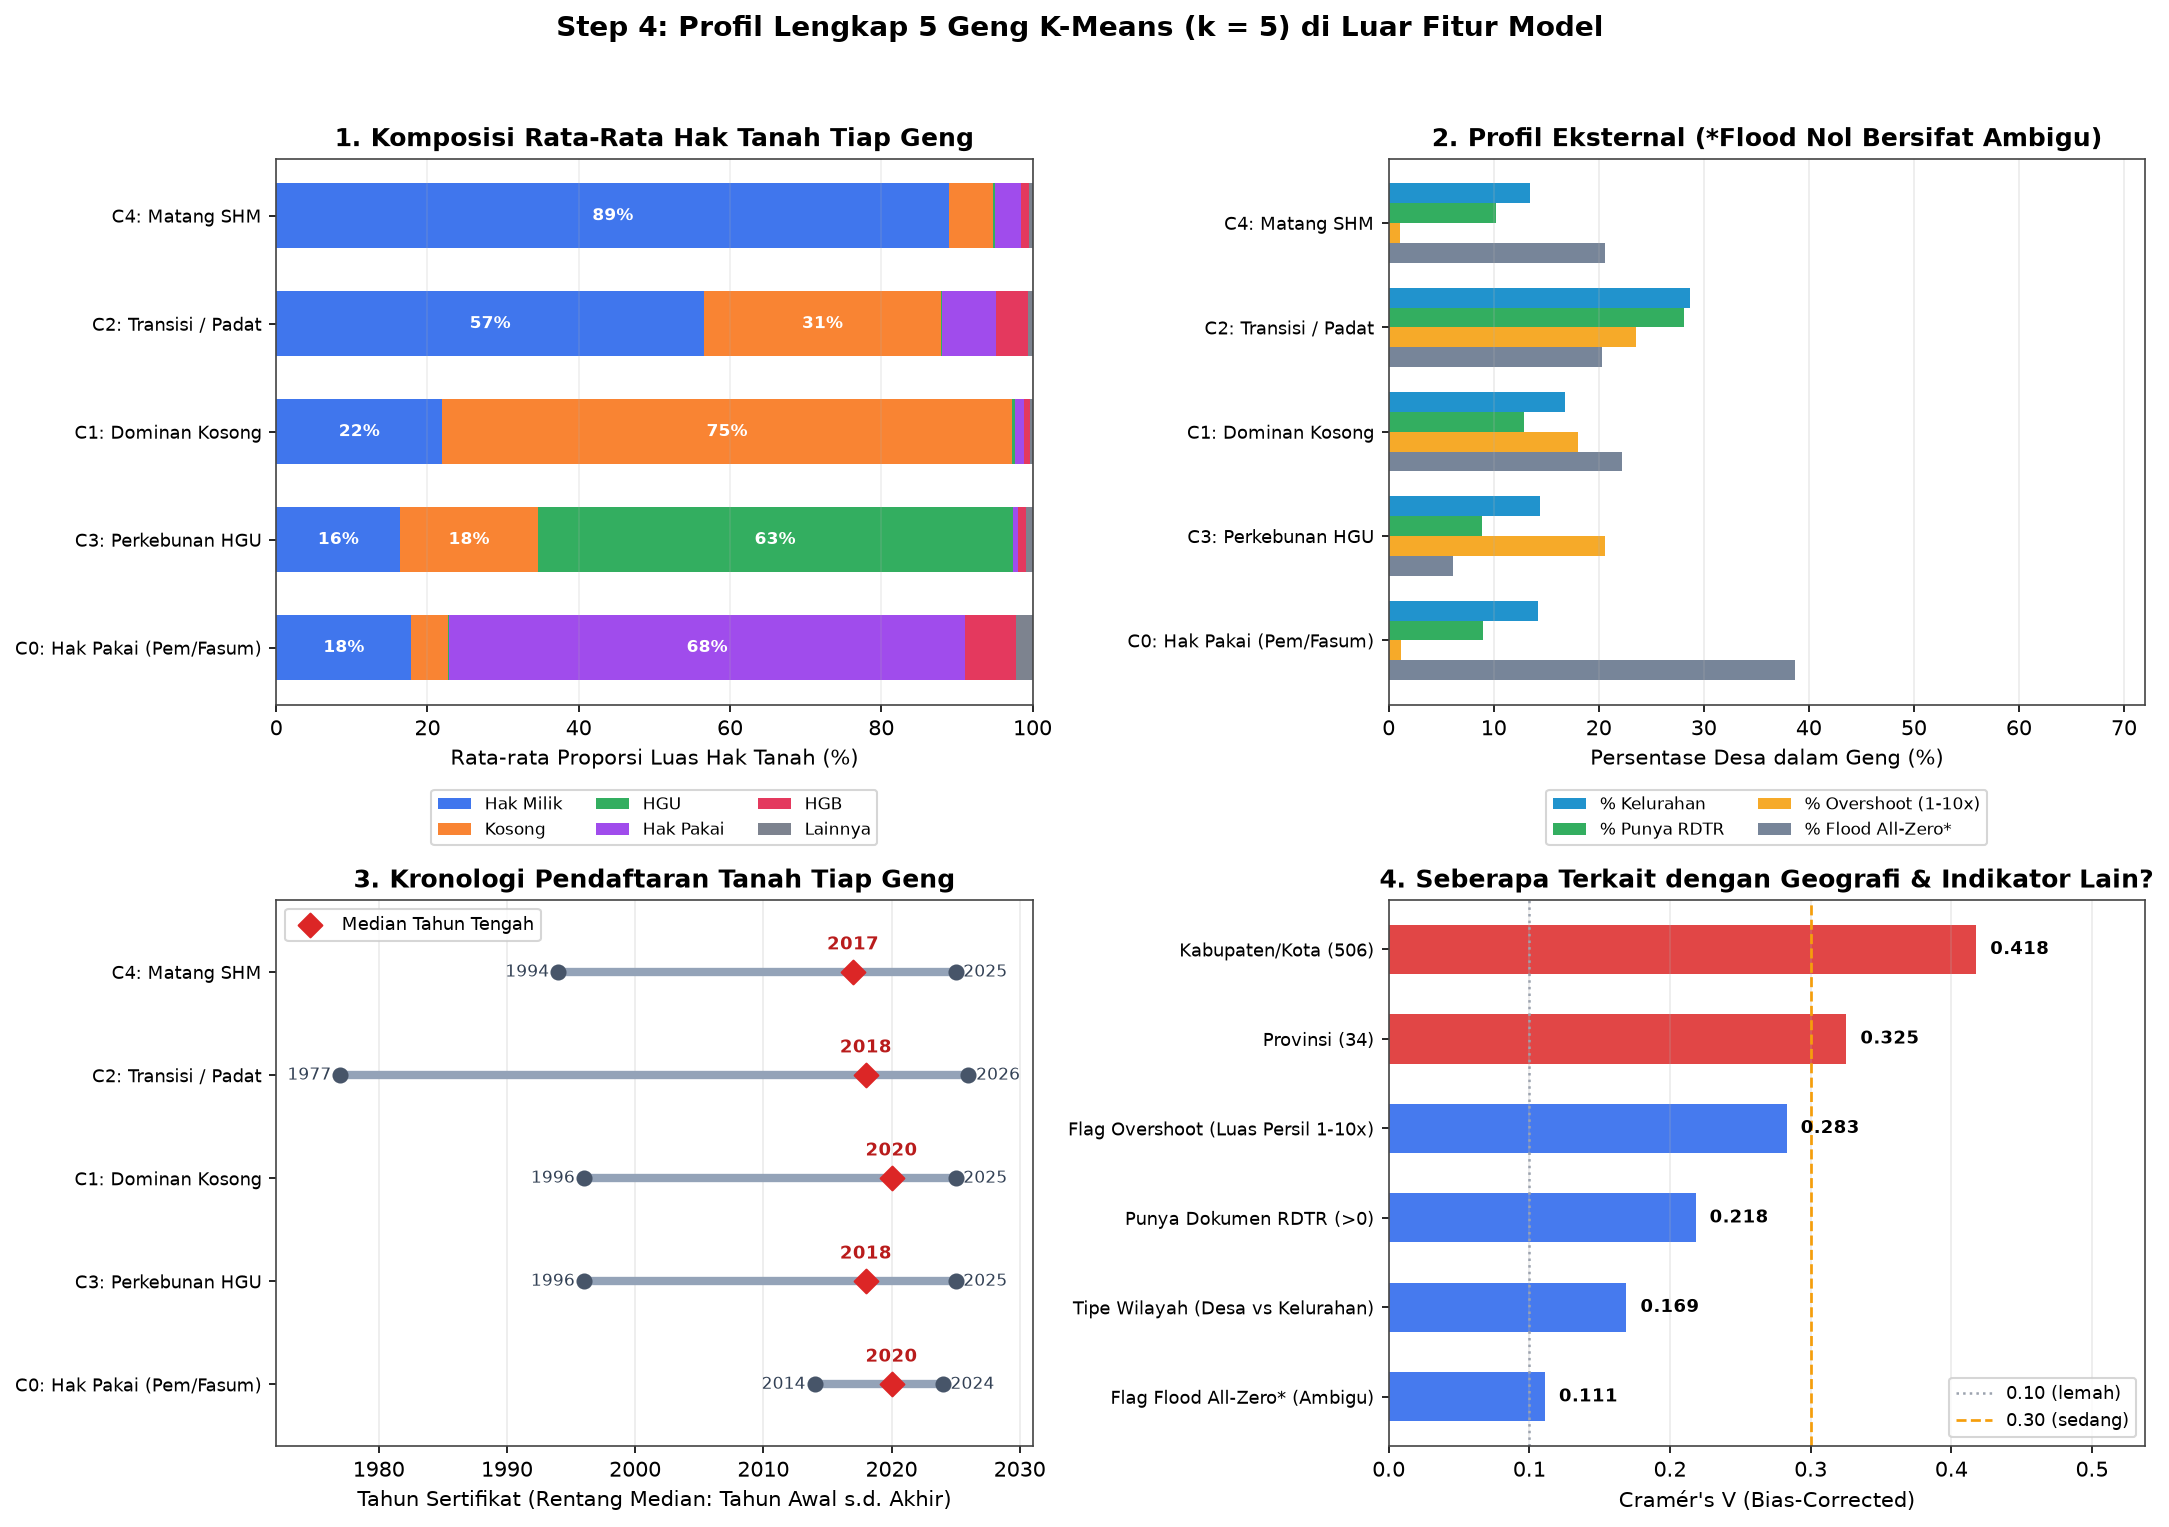

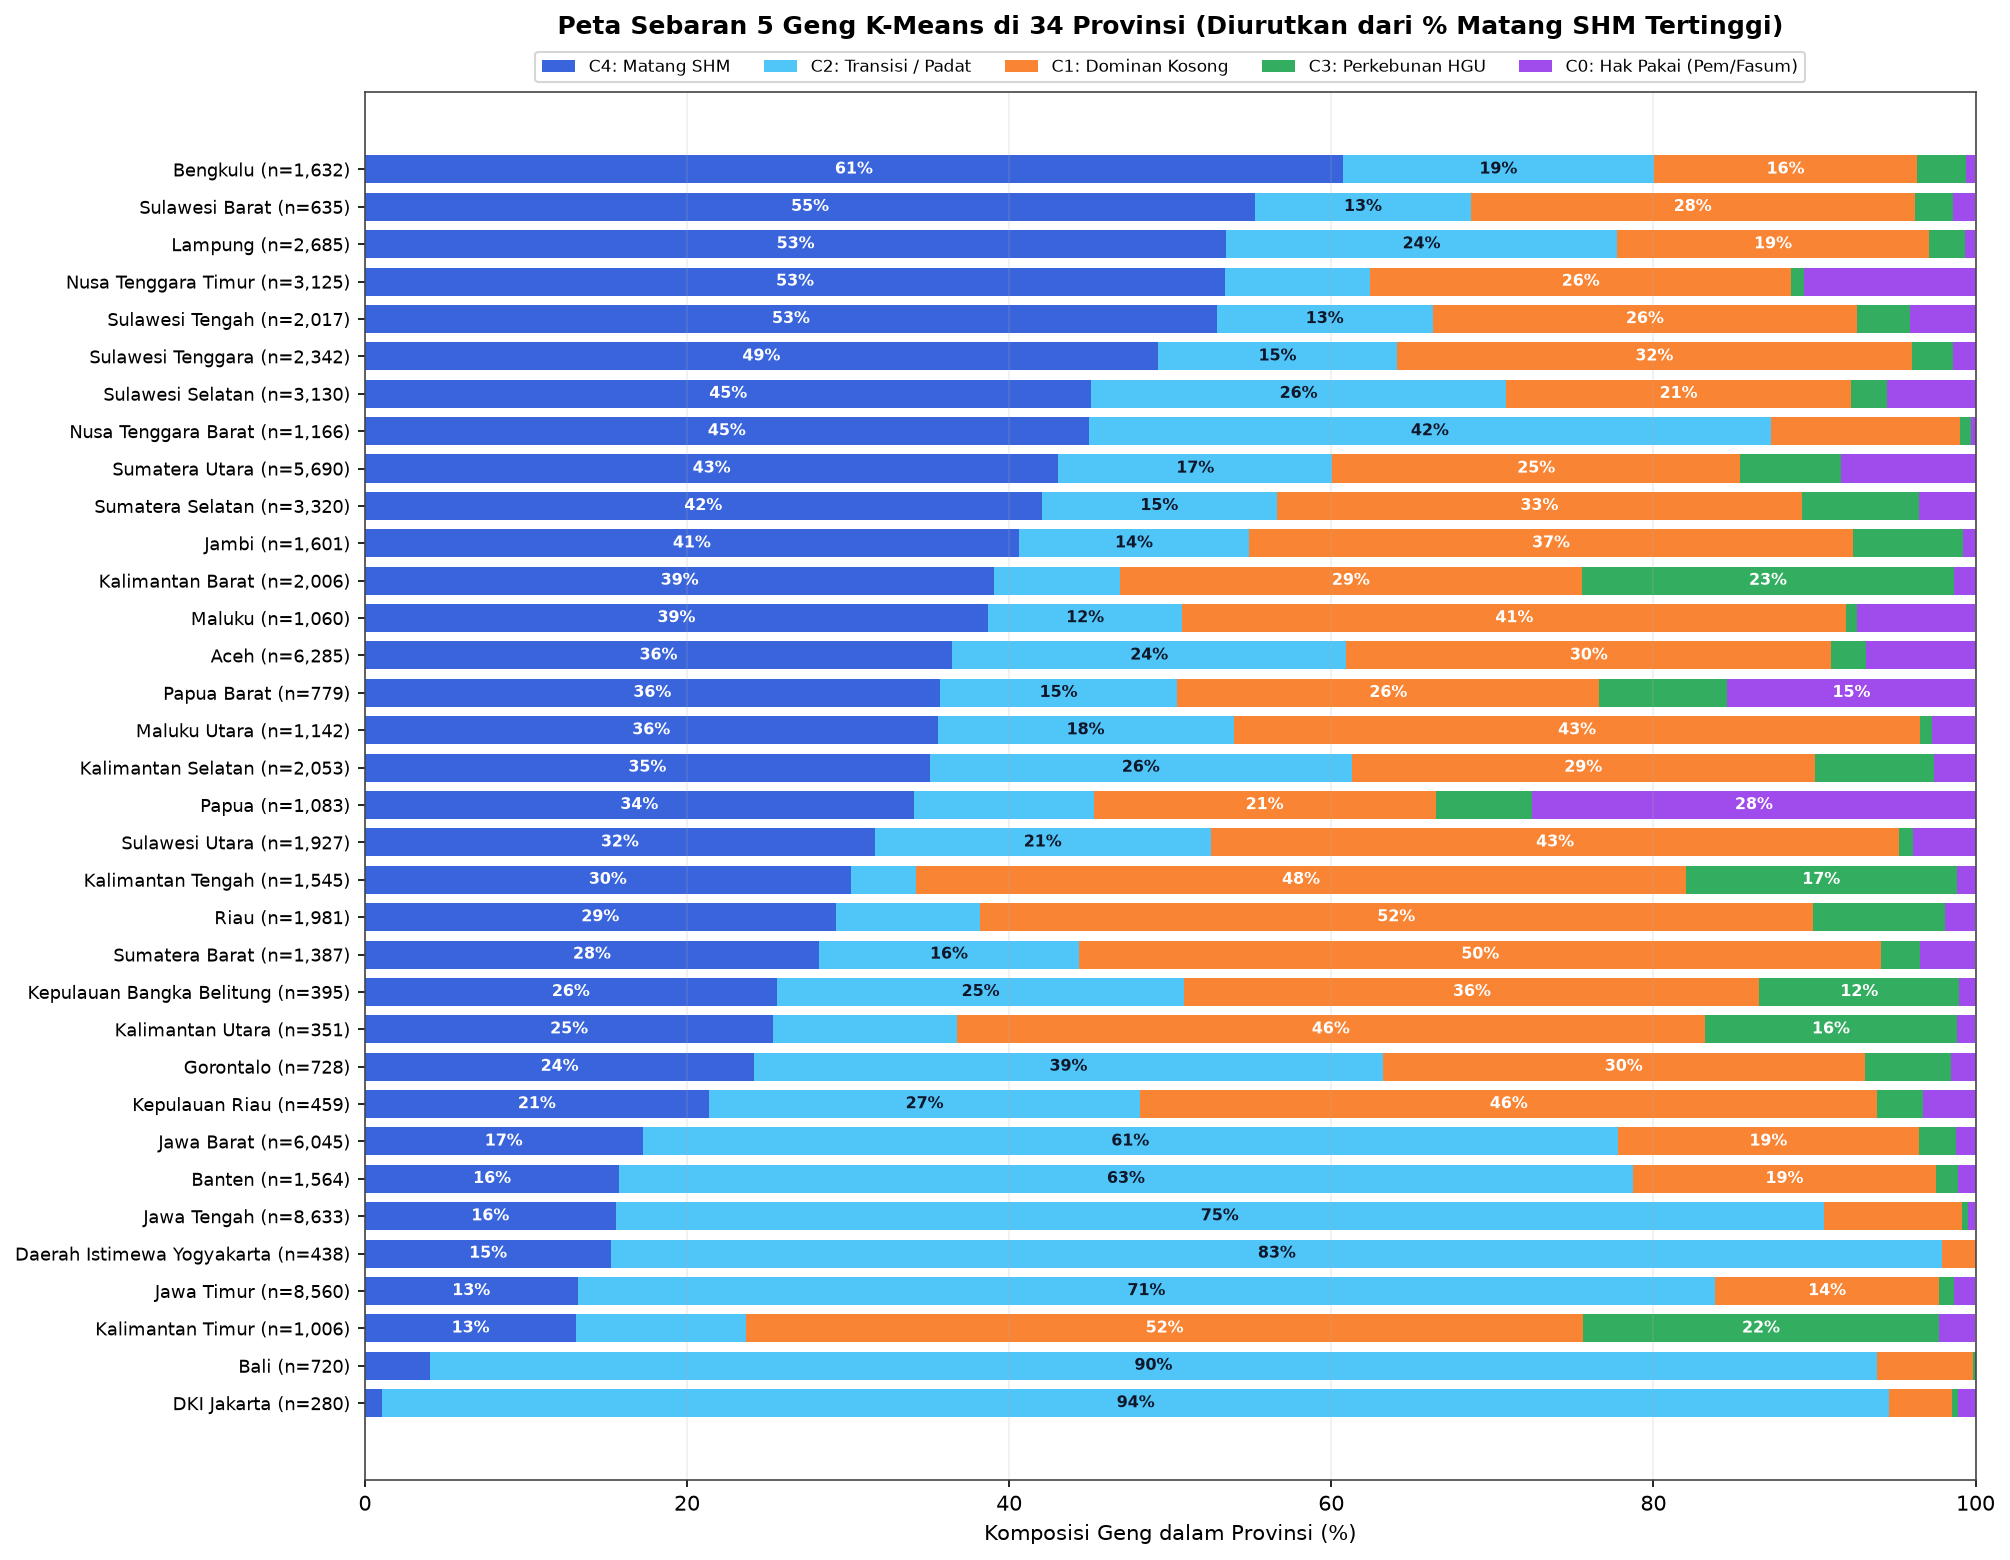

Saved: /Users/otnansirk/S2-MMI/DATA-SCIENCE/spatial-pertanahan-nasional/modeling/outputs/step4_summary.json


In [17]:
# 4.3 Visualisasi Profil Lengkap 5 Geng & Sebaran 34 Provinsi (Inline) + Simpan step4_summary.json
fig, axes = plt.subplots(2, 2, figsize=(14.5, 10.5), dpi=150)

# Panel 1: 100% Stacked Bar Komposisi Hak Tanah (Rata-rata Luas)
ax = axes[0, 0]
right_cols = ["Hak Milik", "Kosong", "HGU", "Hak Pakai", "HGB", "Lainnya"]
right_colors = ["#2563eb", "#f97316", "#16a34a", "#9333ea", "#e11d48", "#6b7280"]
y_idx = np.arange(len(ordered_labels))
left_acc = np.zeros(len(ordered_labels))
comp_plot_df = mean_comp_df.loc[ordered_labels[::-1]]
labels_rev = ordered_labels[::-1]

for rcol, rcolor in zip(right_cols, right_colors):
    vals = comp_plot_df[rcol].to_numpy()
    ax.barh(y_idx, vals, left=left_acc, color=rcolor, alpha=0.88, label=rcol, height=0.6)
    for yi, (lf, vl) in enumerate(zip(left_acc, vals)):
        if vl >= 9.0:
            ax.text(lf + vl / 2, yi, f"{vl:.0f}%", ha="center", va="center", color="white", fontsize=8, fontweight="bold")
    left_acc += vals

ax.set_yticks(y_idx)
ax.set_yticklabels(labels_rev, fontsize=8.5)
ax.set_xlim(0, 100)
ax.set_xlabel("Rata-rata Proporsi Luas Hak Tanah (%)")
ax.set_title("1. Komposisi Rata-Rata Hak Tanah Tiap Geng", fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8, frameon=True)
ax.grid(axis="x", alpha=0.2)

# Panel 2: Indikator Eksternal (% Kelurahan, % RDTR, % Overshoot, % Flood All-Zero*)
ax = axes[0, 1]
ext_metrics = [
    ("Kelurahan%", "% Kelurahan", "#0284c7"),
    ("rdtr_has%", "% Punya RDTR", "#16a34a"),
    ("overshoot%", "% Overshoot (1-10x)", "#f59e0b"),
    ("flood_all_zero%", "% Flood All-Zero*", "#64748b"),
]
h_bar = 0.19
for m_i, (mcol, mlabel, mcolor) in enumerate(ext_metrics):
    vals = master_profile_df.loc[labels_rev, mcol].to_numpy()
    offs = y_idx + (1.5 - m_i) * h_bar
    ax.barh(offs, vals, height=h_bar, color=mcolor, alpha=0.88, label=mlabel)
ax.set_yticks(y_idx)
ax.set_yticklabels(labels_rev, fontsize=8.5)
ax.set_xlim(0, 72)
ax.set_xlabel("Persentase Desa dalam Geng (%)")
ax.set_title("2. Profil Eksternal (*Flood Nol Bersifat Ambigu)", fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, fontsize=8, frameon=True)
ax.grid(axis="x", alpha=0.25)

# Panel 3: Kronologi Sertifikasi (Median tahun_min -> tahun_median -> tahun_max)
ax = axes[1, 0]
for yi, lbl in enumerate(labels_rev):
    tmin = master_profile_df.loc[lbl, "med_tahun_min"]
    tmed = master_profile_df.loc[lbl, "med_tahun_median"]
    tmax = master_profile_df.loc[lbl, "med_tahun_max"]
    ax.plot([tmin, tmax], [yi, yi], color="#94a3b8", lw=4, solid_capstyle="round", zorder=2)
    ax.scatter([tmin, tmax], [yi, yi], color="#475569", s=45, zorder=3)
    ax.scatter([tmed], [yi], color="#dc2626", marker="D", s=65, zorder=4, label="Median Tahun Tengah" if yi == 0 else None)
    ax.text(tmin - 0.7, yi, f"{tmin}", ha="right", va="center", fontsize=8, color="#334155")
    ax.text(tmax + 0.6, yi, f"{tmax}", ha="left", va="center", fontsize=8, color="#334155")
    ax.text(tmed, yi + 0.18, f"{tmed}", ha="center", va="bottom", fontsize=8.5, fontweight="bold", color="#b91c1c")
ax.set_yticks(y_idx)
ax.set_yticklabels(labels_rev, fontsize=8.5)
ax.set_xlim(1972, 2031)
ax.set_ylim(-0.6, len(labels_rev) - 0.3)
ax.set_xlabel("Tahun Sertifikat (Rentang Median: Tahun Awal s.d. Akhir)")
ax.set_title("3. Kronologi Pendaftaran Tanah Tiap Geng", fontweight="bold")
ax.legend(loc="upper left", fontsize=8.5, frameon=True)
ax.grid(axis="x", alpha=0.25)

# Panel 4: Cramer's V (Bias-Corrected) Asosiasi Geografi & Eksternal
ax = axes[1, 1]
assoc_plot = assoc_df.sort_values("cramers_v_corr", ascending=True)
ya = np.arange(len(assoc_plot))
bar_cols = ["#dc2626" if v >= 0.30 else "#2563eb" for v in assoc_plot["cramers_v_corr"]]
ax.barh(ya, assoc_plot["cramers_v_corr"], color=bar_cols, alpha=0.85, height=0.55)
for yi, val in zip(ya, assoc_plot["cramers_v_corr"]):
    ax.text(val + 0.01, yi, f"{val:.3f}", va="center", ha="left", fontsize=8.5, fontweight="bold")
ax.axvline(0.10, color="#9ca3af", ls=":", lw=1.2, label="0.10 (lemah)")
ax.axvline(0.30, color="#f59e0b", ls="--", lw=1.3, label="0.30 (sedang)")
ax.set_yticks(ya)
ax.set_yticklabels(assoc_plot["deskripsi"], fontsize=8.5)
ax.set_xlim(0, max(assoc_plot["cramers_v_corr"]) + 0.12)
ax.set_xlabel("Cramér's V (Bias-Corrected)")
ax.set_title("4. Seberapa Terkait dengan Geografi & Indikator Lain?", fontweight="bold")
ax.legend(loc="lower right", fontsize=8.5, frameon=True)
ax.grid(axis="x", alpha=0.25)

fig.suptitle("Step 4: Profil Lengkap 5 Geng K-Means (k = 5) di Luar Fitur Model", fontsize=13.5, fontweight="bold", y=0.995)
fig.tight_layout(rect=[0, 0.03, 1, 0.97])
plt.show()

# Figure 2: Peta Sebaran 5 Geng di Seluruh 34 Provinsi
prov_ordered_pct = prov_pct[ordered_labels].sort_values(by=ordered_labels[0], ascending=True)
prov_totals = prov_counts.sum(axis=1).loc[prov_ordered_pct.index]

fig, ax = plt.subplots(figsize=(13.5, 10.5), dpi=150)
yp = np.arange(len(prov_ordered_pct))
left_p = np.zeros(len(prov_ordered_pct))
cluster_palette = ["#1d4ed8", "#38bdf8", "#f97316", "#16a34a", "#9333ea"]

for cname, col_hex in zip(ordered_labels, cluster_palette):
    vals = prov_ordered_pct[cname].to_numpy()
    ax.barh(yp, vals, left=left_p, color=col_hex, alpha=0.88, label=cname, height=0.75)
    for yi, (lf, vl) in enumerate(zip(left_p, vals)):
        if vl >= 12.0:
            txt_c = "white" if col_hex != "#38bdf8" else "#0f172a"
            ax.text(lf + vl / 2, yi, f"{vl:.0f}%", ha="center", va="center", color=txt_c, fontsize=7.5, fontweight="bold")
    left_p += vals

ax.set_yticks(yp)
ax.set_yticklabels([f"{p} (n={int(prov_totals[p]):,})" for p in prov_ordered_pct.index], fontsize=8.5)
ax.set_xlim(0, 100)
ax.set_xlabel("Komposisi Geng dalam Provinsi (%)")
ax.set_title("Peta Sebaran 5 Geng K-Means di 34 Provinsi (Diurutkan dari % Matang SHM Tertinggi)", fontweight="bold", pad=28)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.035), ncol=5, fontsize=8, frameon=True)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
plt.show()

# Simpan ringkasan Step 4 ke JSON
step4_summary = {
    "associations": assoc_df.to_dict(orient="records"),
    "master_profile": master_profile_df.reset_index().to_dict(orient="records"),
    "mean_composition": mean_comp_df.round(2).reset_index().to_dict(orient="records"),
    "top_provinces_per_cluster": top_prov_summary,
    "province_breakdown_34": {
        str(p): {cname: round(float(prov_pct.loc[p, cname]), 2) for cname in ordered_labels} | {"n_fit": int(prov_counts.loc[p].sum())}
        for p in prov_ordered_pct.index[::-1]
    },
    "typical_villages_per_cluster": typical_villages,
}
with open(OUT_DIR / "step4_summary.json", "w", encoding="utf-8") as f:
    json.dump(step4_summary, f, indent=2, ensure_ascii=False)
print("Saved:", OUT_DIR / "step4_summary.json")

### Vonis Step 4

- **Bukan fotokopi peta provinsi:** Cramér's V terhadap `provinsi` = `0,325` (`NMI = 0,088`) dan terhadap `kab_key` = `0,418` (`NMI = 0,093`). Klaster benar-benar memisahkan karakter struktural pertanahan (luas/kepadatan, RDTR, overshoot), bukan sekadar batas wilayah.
- **Temuan paling krusial (*coverage* vs komposisi):**
  - **`C4: Matang SHM` (`31,97%`)** memiliki median SHM `92,4%`, tetapi hanya median `368` persil dengan `coverage` `0,163` (banyak di Bengkulu `60,7%`, Sulbar `55,3%`, Lampung `53,5%`, NTT `53,4%`).
  - **`C2: Transisi / Padat` (`35,61%`)** justru mendominasi Jawa–Bali & perkotaan (DKI Jakarta `93,6%`, Bali `89,9%`, DIY `82,6%`, Jateng `75,0%`, Jatim `70,6%`): paling padat (`2.088` persil, `coverage` `0,896`, `28,7% Kelurahan`, `23,5% overshoot`), paling siap RDTR (`28,1%`), kronologi tertua (`1977–2026`), dengan sisa `30,8%` bidang `Kosong` yang perlu dituntaskan.
  - **`C1: Dominan Kosong` (`24,89%`)** adalah target utama sertifikasi PTSL (median Kosong `76,9%`, `coverage` `0,786`, tahun muda `2020`, kuat di Kaltim `52,0%`, Riau `51,7%`, Sumbar `49,8%`, Kalteng `47,8%`).
  - **`C3: Perkebunan HGU` (`3,94%`)** berwilayah luas (median `4.045` ha, median HGU `64,2%`, kuat di Kalimantan: Kalbar `23,1%`, Kaltim `22,1%`, Kalteng `16,8%`).
  - **`C0: Hak Pakai` (`3,58%`)** hanya memiliki median `9` persil (`coverage` `0,007`, tahun muda `2014–2024`, tinggi di Papua `27,5%`, Papua Barat `15,4%`, NTT `10,6%`) dan paling banyak `flood_all_zero` (`38,7%`, ambigu secara regional).

---

## Step 5: Kasih Julukan, Laporkan `place_later` & Rekomendasi Kebijakan (Next)